
# P5 — Cross-City Transfer Learning for PV Power Prediction

## 1. Objective

This experiment investigates whether knowledge acquired from a data-rich photovoltaic (PV) installation can improve power prediction at a different installation where only a small amount of labeled data is available.

The central objective is to transfer predictive knowledge from Davis to Amherst and evaluate whether transfer learning outperforms zero-shot and target-only few-shot baselines.

## 2. Source and Target Domains

**Source domain:** Davis, six-year dataset.

**Target domain:** Amherst, three-year dataset.

The prediction target is continuous **Output Power (kW)**.

The existing chronological training and held-out test partitions are retained. The Amherst test partition is reserved for final evaluation.

## 3. Few-Shot Label Budgets

The experiment considers three target-domain labeled-data budgets:

- 10 labeled Amherst observations
- 50 labeled Amherst observations
- 100 labeled Amherst observations

Three random seeds are used: 42, 123, and 2026.

Identical target-domain labeled subsets are used for competing methods under each configuration.

## 4. Baseline Approaches

### 4.1 Zero-Shot Transfer

A regression model is trained using labeled Davis observations and applied directly to Amherst without using Amherst power labels for adaptation.

### 4.2 Target-Only Few-Shot Learning

A regression model is trained exclusively using the available 10, 50, or 100 labeled Amherst observations.

These approaches establish the source-only and target-only reference performance.

## 5. Transfer-Learning Approaches

The experiment investigates methods that combine source-domain knowledge with limited target-domain supervision, including:

1. Source-model fine-tuning using limited target labels.
2. Joint source-target learning with domain-aware weighting.
3. Target-domain calibration or residual correction of source predictions.

Classical regression models and a neural-network-based transfer approach are evaluated.

## 6. Experimental Controls

- Chronological train/test partitions are preserved.
- The same target-label budgets and random seeds are used for paired comparisons.
- Feature preprocessing and any target-domain adaptation use permitted training observations only.
- Source and target feature definitions are aligned.
- Differences in PV output scales are accounted for using training-derived transformations or calibration.
- The held-out Amherst test partition is excluded from training, adaptation, and model selection.

## 7. Evaluation Metrics

Prediction quality is evaluated using:

- Root Mean Squared Error (RMSE), in kW
- Mean Absolute Error (MAE), in kW
- Normalized Root Mean Squared Error (nRMSE)
- Transfer gain relative to source-only and target-only baselines

Results are summarized using the mean and standard deviation across three random seeds.

## 8. Analysis and Visualization

The analysis compares zero-shot, few-shot, and transfer-learning performance across all three target-label budgets.

Visualizations include target-label-efficiency curves, model comparisons, and prediction-versus-ground-truth plots.

The final discussion examines positive transfer, negative transfer, cross-city distribution shifts, and the impact of target-domain data scarcity.




In [1]:

# ============================================================
# P5 — Cell 2: Environment Setup and Dataset Verification
# ============================================================

import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from IPython.display import display


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 2. Locate the project directory
# ------------------------------------------------------------

PROJECT_ROOT_OVERRIDE = None


def locate_p5_project_root():

    if PROJECT_ROOT_OVERRIDE is not None:
        root = Path(
            PROJECT_ROOT_OVERRIDE
        ).expanduser().resolve()

        if (root / "Data" / "Processed").is_dir():
            return root

        raise FileNotFoundError(
            f"Invalid project root: {root}"
        )

    current = Path.cwd().resolve()

    for candidate in (current, *current.parents):

        if (candidate / "Data" / "Processed").is_dir():
            return candidate

    if IN_COLAB:

        root = (
            Path("/content/drive/MyDrive")
            / "Colab Notebooks"
            / "ML_ECE_571_Project"
            / "Code_base_v2"
        )

        if (root / "Data" / "Processed").is_dir():
            return root

    raise FileNotFoundError(
        "Project root not found. "
        "Set PROJECT_ROOT_OVERRIDE manually."
    )


PROJECT_ROOT = locate_p5_project_root()

PROCESSED_DIR = PROJECT_ROOT / "Data" / "Processed"
SPLITS_DIR = PROCESSED_DIR / "Splits"

RESULTS_DIR = PROJECT_ROOT / "Results" / "P5"
FIGURES_DIR = PROJECT_ROOT / "Figures" / "P5"
PREDICTIONS_DIR = RESULTS_DIR / "Predictions"
MODELS_DIR = RESULTS_DIR / "Models"
FEW_SHOT_DIR = RESULTS_DIR / "Few_Shot_Splits"

for folder in (
    RESULTS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    MODELS_DIR,
    FEW_SHOT_DIR
):
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 3. Experimental configuration
# ------------------------------------------------------------

SEEDS = (42, 123, 2026)

TARGET_LABEL_BUDGETS = (10, 50, 100)

SOURCE_CITY = "Davis"
TARGET_CITY = "Amherst"

TARGET_COLUMN = "Output Power"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ------------------------------------------------------------
# 4. Locate the Davis six-year dataset
# ------------------------------------------------------------

# Discover the six-year file using its observed size and
# number of years rather than assuming its filename.

davis_candidates = []

for path in sorted(
    PROCESSED_DIR.glob("Davis_*.csv")
):

    candidate = pd.read_csv(
        path,
        usecols=["Timestamp"],
        parse_dates=["Timestamp"]
    )

    if (
        len(candidate) > 20000
        and candidate["Timestamp"].dt.year.nunique() == 6
    ):
        davis_candidates.append(path)

if len(davis_candidates) != 1:
    raise RuntimeError(
        "Expected exactly one Davis six-year dataset. "
        f"Candidates found: {davis_candidates}"
    )

SOURCE_PATH = davis_candidates[0]

# Amherst is the three-year dataset already used in P1–P4.
TARGET_PATH = (
    PROCESSED_DIR / "Amherst_2018_2020.csv"
)

if not TARGET_PATH.is_file():
    raise FileNotFoundError(
        f"Missing Amherst dataset: {TARGET_PATH}"
    )

DATASET_PATHS = {
    "Source": SOURCE_PATH,
    "Target": TARGET_PATH
}


# ------------------------------------------------------------
# 5. Load datasets and verify chronological partitions
# ------------------------------------------------------------

P5_DATA = {}
dataset_summary = []

required_columns = (
    "Timestamp",
    "row_index",
    "Output Power",
    "Cloud Type"
)

for domain, data_path in DATASET_PATHS.items():

    split_path = (
        SPLITS_DIR
        / f"{data_path.stem}_chronological_80_20.csv"
    )

    if not split_path.is_file():
        raise FileNotFoundError(
            f"Missing split manifest: {split_path}"
        )

    df = pd.read_csv(
        data_path,
        parse_dates=["Timestamp"]
    )

    split_df = pd.read_csv(
        split_path,
        parse_dates=["Timestamp"]
    )

    for column in required_columns:
        assert column in df.columns, (
            f"{domain}: Missing column {column}"
        )

    assert len(df) == len(split_df)

    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        split_df["row_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        split_df["Timestamp"].to_numpy()
    )

    assert df["Timestamp"].is_monotonic_increasing

    assert not df["Timestamp"].duplicated().any()

    train_mask = split_df[
        "split"
    ].eq("train").to_numpy()

    test_mask = split_df[
        "split"
    ].eq("test").to_numpy()

    assert np.all(train_mask | test_mask)
    assert not np.any(train_mask & test_mask)

    assert train_mask.sum() == int(
        0.80 * len(df)
    )

    assert (
        df.loc[train_mask, "Timestamp"].max()
        < df.loc[test_mask, "Timestamp"].min()
    )

    power = pd.to_numeric(
        df[TARGET_COLUMN],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_power = np.isfinite(power)

    # Training observations used for regression require
    # valid target power measurements.
    valid_train_mask = train_mask & valid_power
    valid_test_mask = test_mask & valid_power

    # Original chronological partitions remain unchanged.
    # Invalid power observations are excluded only when
    # supervised target values are required.

    P5_DATA[domain] = {
        "city": SOURCE_CITY if domain == "Source" else TARGET_CITY,
        "filename": data_path.name,
        "data": df,
        "train_mask": train_mask,
        "test_mask": test_mask,
        "valid_train_mask": valid_train_mask,
        "valid_test_mask": valid_test_mask,
        "train_rows": np.flatnonzero(
            valid_train_mask
        ),
        "test_rows": np.flatnonzero(
            valid_test_mask
        )
    }

    dataset_summary.append({
        "Domain": domain,
        "City": P5_DATA[domain]["city"],
        "Years": df["Timestamp"].dt.year.nunique(),
        "Total Samples": len(df),
        "Train Samples": int(train_mask.sum()),
        "Valid Train Targets": int(
            valid_train_mask.sum()
        ),
        "Test Samples": int(test_mask.sum()),
        "Valid Test Targets": int(
            valid_test_mask.sum()
        ),
        "First Date": df["Timestamp"].min().date(),
        "Last Date": df["Timestamp"].max().date()
    })

    print(
        f"[PASS] {domain}: {data_path.name}",
        flush=True
    )


# ------------------------------------------------------------
# 6. Validate the intended transfer-learning scenario
# ------------------------------------------------------------

source_data = P5_DATA["Source"]
target_data = P5_DATA["Target"]

assert (
    source_data["data"]["Timestamp"].dt.year.nunique()
    == 6
)

assert (
    target_data["data"]["Timestamp"].dt.year.nunique()
    == 3
)

assert (
    len(source_data["train_rows"])
    > len(target_data["train_rows"])
)

assert (
    len(target_data["train_rows"])
    >= max(TARGET_LABEL_BUDGETS)
)

# Feature alignment will be implemented in Cell 3.
# Only columns common to source and target can be used.

source_columns = set(
    source_data["data"].columns
)

target_columns = set(
    target_data["data"].columns
)

common_columns = source_columns & target_columns

assert "Output Power" in common_columns
assert "GHI" in common_columns
assert "Cloud Type" in common_columns


# ------------------------------------------------------------
# 7. Display verification summary
# ------------------------------------------------------------

print("\nP5 — TRANSFER LEARNING SETUP")
print("=" * 75)

print(f"Environment         : {'Colab' if IN_COLAB else 'Local'}")
print(f"Python version      : {platform.python_version()}")
print(f"PyTorch version     : {torch.__version__}")
print(f"Compute device      : {DEVICE}")

if torch.cuda.is_available():
    print(
        f"GPU                 : "
        f"{torch.cuda.get_device_name(0)}"
    )

print(f"\nProject root        : {PROJECT_ROOT}")
print(f"Source city         : {SOURCE_CITY}")
print(f"Target city         : {TARGET_CITY}")
print(f"Prediction target   : {TARGET_COLUMN}")
print(f"Few-shot budgets    : {TARGET_LABEL_BUDGETS}")
print(f"Random seeds        : {SEEDS}")

print("\nDATASET SUMMARY")
display(pd.DataFrame(dataset_summary))

print("\nSOURCE DATASET")
print(SOURCE_PATH)

print("\nTARGET DATASET")
print(TARGET_PATH)

print("\nFEATURE COMPATIBILITY")
print(f"Source columns      : {len(source_columns)}")
print(f"Target columns      : {len(target_columns)}")
print(f"Common columns      : {len(common_columns)}")

print("\nOUTPUT DIRECTORIES")
print(f"Results             : {RESULTS_DIR}")
print(f"Figures             : {FIGURES_DIR}")
print(f"Predictions         : {PREDICTIONS_DIR}")
print(f"Models              : {MODELS_DIR}")
print(f"Few-shot splits     : {FEW_SHOT_DIR}")

print("\nAll P5 dataset checks passed.")
print("No models have been trained.")
print("No target-label subsets have been selected.")


Mounted at /content/drive
[PASS] Source: Davis_2011_2016.csv
[PASS] Target: Amherst_2018_2020.csv

P5 — TRANSFER LEARNING SETUP
Environment         : Colab
Python version      : 3.13.16
PyTorch version     : 2.11.0+cu130
Compute device      : cuda
GPU                 : Tesla T4

Project root        : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2
Source city         : Davis
Target city         : Amherst
Prediction target   : Output Power
Few-shot budgets    : (10, 50, 100)
Random seeds        : (42, 123, 2026)

DATASET SUMMARY


,Domain,City,Years,Total Samples,Train Samples,Valid Train Targets,Test Samples,Valid Test Targets,First Date,Last Date
0,Source,Davis,6,24112,19289,19289,4823,4823,2011-01-01,2016-12-31
1,Target,Amherst,3,12056,9644,9644,2412,2408,2018-01-01,2020-12-31



SOURCE DATASET
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Data/Processed/Davis_2011_2016.csv

TARGET DATASET
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Data/Processed/Amherst_2018_2020.csv

FEATURE COMPATIBILITY
Source columns      : 24
Target columns      : 24
Common columns      : 24

OUTPUT DIRECTORIES
Results             : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5
Figures             : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P5
Predictions         : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Predictions
Models              : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Models
Few-shot splits     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Few_Shot_Splits

All P5 dataset checks passed.
No models have been trained.
No target-label subse

In [2]:

# ============================================================
# P5 — Cell 3: Feature Alignment and Few-Shot Sampling
# ============================================================

# ------------------------------------------------------------
# 1. Define common source/target features
# ------------------------------------------------------------

# Absolute Year is excluded because the source and target
# datasets cover different calendar periods.

P5_NUMERIC_FEATURES = [
    "Month", "Day", "Hour", "Minute",
    "DHI", "DNI", "GHI",
    "Clearsky DHI", "Clearsky DNI", "Clearsky GHI",
    "Dew Point", "Solar Zenith Angle", "Surface Albedo",
    "Wind Speed", "Precipitable Water", "Wind Direction",
    "Relative Humidity", "Temperature", "Pressure",
    "Hour_Sin", "Hour_Cos",
    "DayOfYear_Sin", "DayOfYear_Cos"
]

P5_CATEGORICAL_FEATURES = ["Cloud Type"]

P5_FEATURES = (
    P5_NUMERIC_FEATURES
    + P5_CATEGORICAL_FEATURES
)


def prepare_p5_features(df):
    """
    Construct a common input representation for both
    cities without using Output Power values.
    """

    X = df.copy()

    # Daily periodicity
    hour = (
        X["Hour"].to_numpy(dtype=float)
        + X["Minute"].to_numpy(dtype=float) / 60.0
    )

    X["Hour_Sin"] = np.sin(
        2 * np.pi * hour / 24.0
    )

    X["Hour_Cos"] = np.cos(
        2 * np.pi * hour / 24.0
    )

    # Annual periodicity
    day_of_year = (
        X["Timestamp"]
        .dt.dayofyear
        .to_numpy(dtype=float)
    )

    X["DayOfYear_Sin"] = np.sin(
        2 * np.pi * (day_of_year - 1) / 365.25
    )

    X["DayOfYear_Cos"] = np.cos(
        2 * np.pi * (day_of_year - 1) / 365.25
    )

    missing = [
        feature for feature in P5_FEATURES
        if feature not in X.columns
    ]

    if missing:
        raise ValueError(
            f"Missing input features: {missing}"
        )

    X["Cloud Type"] = (
        X["Cloud Type"]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

    features = X[P5_FEATURES].copy()

    numerical_values = features[
        P5_NUMERIC_FEATURES
    ].to_numpy(dtype=float)

    if not np.isfinite(numerical_values).all():
        raise ValueError(
            "Non-finite numerical input features detected."
        )

    return features


# ------------------------------------------------------------
# 2. Prepare source and target partitions
# ------------------------------------------------------------

P5_PARTITIONS = {}

for domain in ("Source", "Target"):

    dataset = P5_DATA[domain]
    df = dataset["data"]

    X_all = prepare_p5_features(df)

    power = pd.to_numeric(
        df[TARGET_COLUMN],
        errors="coerce"
    ).to_numpy(dtype=float)

    train_rows = dataset["train_rows"]
    test_rows = dataset["test_rows"]

    X_train = (
        X_all.iloc[train_rows]
        .reset_index(drop=True)
    )

    X_test = (
        X_all.iloc[test_rows]
        .reset_index(drop=True)
    )

    y_train = power[train_rows].copy()
    y_test = power[test_rows].copy()

    train_row_index = (
        df.iloc[train_rows]["row_index"]
        .to_numpy()
        .copy()
    )

    test_row_index = (
        df.iloc[test_rows]["row_index"]
        .to_numpy()
        .copy()
    )

    assert np.isfinite(y_train).all()
    assert np.isfinite(y_test).all()

    assert len(X_train) == len(y_train)
    assert len(X_test) == len(y_test)

    assert np.isin(
        train_row_index,
        test_row_index
    ).sum() == 0

    P5_PARTITIONS[domain] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "train_row_index": train_row_index,
        "test_row_index": test_row_index
    }

    print(
        f"[PASS] {domain}: "
        f"{len(X_train):,} training samples, "
        f"{len(X_test):,} valid test samples."
    )


# ------------------------------------------------------------
# 3. Verify identical feature definitions
# ------------------------------------------------------------

source = P5_PARTITIONS["Source"]
target = P5_PARTITIONS["Target"]

assert source["X_train"].columns.tolist() == (
    target["X_train"].columns.tolist()
)

assert source["X_test"].columns.tolist() == (
    target["X_test"].columns.tolist()
)

assert len(P5_FEATURES) == 24

assert TARGET_COLUMN not in P5_FEATURES
assert "Timestamp" not in P5_FEATURES
assert "row_index" not in P5_FEATURES
assert "Year" not in P5_FEATURES

assert len(source["X_train"]) == 19289
assert len(target["X_train"]) == 9644
assert len(target["X_test"]) == 2408


# ------------------------------------------------------------
# 4. Generate reproducible few-shot selection manifests
# ------------------------------------------------------------

# One shuffled ordering is generated for each random seed.
# The 10-sample subset is nested inside the 50-sample
# subset, which is nested inside the 100-sample subset.
#
# Sampling is independent of the target power values.

P5_FEW_SHOT_SPLITS = {}

target_train_ids = target["train_row_index"]

for seed in SEEDS:

    rng = np.random.default_rng(seed)

    permutation = rng.permutation(
        len(target_train_ids)
    )

    selection_rank = np.empty(
        len(target_train_ids),
        dtype=np.int64
    )

    selection_rank[permutation] = np.arange(
        len(target_train_ids)
    )

    manifest = pd.DataFrame({
        "row_index": target_train_ids,
        "selection_rank": selection_rank
    })

    manifest_path = (
        FEW_SHOT_DIR
        / f"Amherst_FewShot_Seed_{seed}.csv"
    )

    if manifest_path.exists():

        previous_manifest = pd.read_csv(
            manifest_path
        )

        # A saved manifest must never change silently.
        pd.testing.assert_frame_equal(
            previous_manifest,
            manifest,
            check_dtype=False
        )

    else:

        manifest.to_csv(
            manifest_path,
            index=False
        )

    P5_FEW_SHOT_SPLITS[seed] = {}

    for budget in TARGET_LABEL_BUDGETS:

        labeled_positions = np.flatnonzero(
            selection_rank < budget
        )

        unlabeled_positions = np.flatnonzero(
            selection_rank >= budget
        )

        assert len(labeled_positions) == budget

        assert (
            len(labeled_positions)
            + len(unlabeled_positions)
            == len(target_train_ids)
        )

        assert not np.intersect1d(
            labeled_positions,
            unlabeled_positions
        ).size

        P5_FEW_SHOT_SPLITS[seed][budget] = {
            "labeled_positions": labeled_positions,
            "unlabeled_positions": unlabeled_positions,

            # Only the selected target labels are made
            # available to the learning methods.
            "y_labeled": target["y_train"][
                labeled_positions
            ].copy()
        }


# ------------------------------------------------------------
# 5. Verify nested few-shot subsets
# ------------------------------------------------------------

for seed in SEEDS:

    positions_10 = set(
        P5_FEW_SHOT_SPLITS[seed][10][
            "labeled_positions"
        ]
    )

    positions_50 = set(
        P5_FEW_SHOT_SPLITS[seed][50][
            "labeled_positions"
        ]
    )

    positions_100 = set(
        P5_FEW_SHOT_SPLITS[seed][100][
            "labeled_positions"
        ]
    )

    assert positions_10.issubset(positions_50)
    assert positions_50.issubset(positions_100)


# ------------------------------------------------------------
# 6. Define the learner-facing experiment interface
# ------------------------------------------------------------

def get_p5_experiment(budget, seed):
    """
    Return source data, the permitted labeled target
    subset, unlabeled target features, and held-out test
    observations.

    The ground-truth labels of the remaining Amherst
    training observations are deliberately not returned.
    """

    budget = int(budget)
    seed = int(seed)

    if budget not in TARGET_LABEL_BUDGETS:
        raise ValueError(
            f"Unsupported target-label budget: {budget}"
        )

    if seed not in SEEDS:
        raise ValueError(
            f"Unsupported random seed: {seed}"
        )

    selected = P5_FEW_SHOT_SPLITS[
        seed
    ][budget]

    labeled = selected["labeled_positions"]
    unlabeled = selected["unlabeled_positions"]

    return {
        # Fully labeled Davis training observations
        "X_source_train": source["X_train"].copy(),
        "y_source_train": source["y_train"].copy(),

        # Only the permitted Amherst target labels
        "X_target_labeled": (
            target["X_train"]
            .iloc[labeled]
            .copy()
        ),

        "y_target_labeled": (
            selected["y_labeled"].copy()
        ),

        # Remaining Amherst feature vectors
        "X_target_unlabeled": (
            target["X_train"]
            .iloc[unlabeled]
            .copy()
        ),

        # Held-out Amherst evaluation data
        "X_target_test": target["X_test"].copy(),
        "y_target_test": target["y_test"].copy(),

        # Stable identifiers for verification and outputs
        "source_train_row_index": (
            source["train_row_index"].copy()
        ),

        "target_labeled_row_index": (
            target["train_row_index"][labeled].copy()
        ),

        "target_unlabeled_row_index": (
            target["train_row_index"][unlabeled].copy()
        ),

        "target_test_row_index": (
            target["test_row_index"].copy()
        )
    }


# ------------------------------------------------------------
# 7. Verify the learner-facing data
# ------------------------------------------------------------

for seed in SEEDS:

    for budget in TARGET_LABEL_BUDGETS:

        experiment = get_p5_experiment(
            budget=budget,
            seed=seed
        )

        assert len(
            experiment["X_source_train"]
        ) == 19289

        assert len(
            experiment["X_target_labeled"]
        ) == budget

        assert len(
            experiment["y_target_labeled"]
        ) == budget

        assert len(
            experiment["X_target_unlabeled"]
        ) == 9644 - budget

        assert len(
            experiment["X_target_test"]
        ) == 2408

        assert len(
            experiment["y_target_test"]
        ) == 2408

        assert "y_target_unlabeled" not in experiment

        # Verify that every dataset has aligned columns.
        columns = experiment[
            "X_source_train"
        ].columns.tolist()

        for name in (
            "X_target_labeled",
            "X_target_unlabeled",
            "X_target_test"
        ):

            assert (
                experiment[name].columns.tolist()
                == columns
            )


# ------------------------------------------------------------
# 8. Display final dataset and sampling summaries
# ------------------------------------------------------------

print("\nP5 — FEATURE AND FEW-SHOT CONFIGURATION")
print("=" * 75)

print(f"Common input features : {len(P5_FEATURES)}")
print(f"Numerical features    : {len(P5_NUMERIC_FEATURES)}")
print(f"Categorical features  : {P5_CATEGORICAL_FEATURES}")

print("\nFEATURE NAMES")
print(", ".join(P5_FEATURES))

summary_rows = []

for seed in SEEDS:

    for budget in TARGET_LABEL_BUDGETS:

        split = P5_FEW_SHOT_SPLITS[
            seed
        ][budget]

        y_selected = split["y_labeled"]

        summary_rows.append({
            "Seed": seed,
            "Amherst Labels": budget,
            "Unlabeled Amherst": (
                len(target["X_train"]) - budget
            ),
            "Selected Power Min (kW)": (
                float(np.min(y_selected))
            ),
            "Selected Power Median (kW)": (
                float(np.median(y_selected))
            ),
            "Selected Power Max (kW)": (
                float(np.max(y_selected))
            )
        })

print("\nFEW-SHOT SAMPLING SUMMARY")
display(
    pd.DataFrame(summary_rows)
    .round(3)
)

print("\nSOURCE AND TARGET DATA AVAILABILITY")
display(
    pd.DataFrame([
        {
            "Domain": "Davis source",
            "Training Features": len(source["X_train"]),
            "Available Training Labels": len(source["y_train"]),
            "Held-Out Test Samples": len(source["X_test"])
        },
        {
            "Domain": "Amherst target",
            "Training Features": len(target["X_train"]),
            "Available Training Labels": "10 / 50 / 100",
            "Held-Out Test Samples": len(target["X_test"])
        }
    ])
)

print("\nSAVED FEW-SHOT MANIFESTS")
for seed in SEEDS:
    print(
        FEW_SHOT_DIR
        / f"Amherst_FewShot_Seed_{seed}.csv"
    )

print("\nAll feature-alignment checks passed.")
print("Few-shot subsets are reproducible and nested.")
print("No hidden target training labels are returned.")
print("No models have been trained.")


[PASS] Source: 19,289 training samples, 4,823 valid test samples.
[PASS] Target: 9,644 training samples, 2,408 valid test samples.

P5 — FEATURE AND FEW-SHOT CONFIGURATION
Common input features : 24
Numerical features    : 23
Categorical features  : ['Cloud Type']

FEATURE NAMES
Month, Day, Hour, Minute, DHI, DNI, GHI, Clearsky DHI, Clearsky DNI, Clearsky GHI, Dew Point, Solar Zenith Angle, Surface Albedo, Wind Speed, Precipitable Water, Wind Direction, Relative Humidity, Temperature, Pressure, Hour_Sin, Hour_Cos, DayOfYear_Sin, DayOfYear_Cos, Cloud Type

FEW-SHOT SAMPLING SUMMARY


,Seed,Amherst Labels,Unlabeled Amherst,Selected Power Min (kW),Selected Power Median (kW),Selected Power Max (kW)
0,42,10,9634,2.483,106.850,124.1
1,42,50,9594,0.900,69.850,129.7
2,42,100,9544,0.000,68.050,129.7
3,123,10,9634,0.000,84.200,126.8
4,123,50,9594,0.000,51.545,126.8
5,123,100,9544,0.000,57.500,126.9
6,2026,10,9634,0.300,51.230,109.3
7,2026,50,9594,0.300,66.300,127.1
8,2026,100,9544,0.200,60.485,129.6



SOURCE AND TARGET DATA AVAILABILITY


,Domain,Training Features,Available Training Labels,Held-Out Test Samples
0,Davis source,19289,19289,4823
1,Amherst target,9644,10 / 50 / 100,2408



SAVED FEW-SHOT MANIFESTS
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Few_Shot_Splits/Amherst_FewShot_Seed_42.csv
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Few_Shot_Splits/Amherst_FewShot_Seed_123.csv
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Few_Shot_Splits/Amherst_FewShot_Seed_2026.csv

All feature-alignment checks passed.
Few-shot subsets are reproducible and nested.
No hidden target training labels are returned.
No models have been trained.


In [3]:

# ============================================================
# P5 — Cell 4: Zero-Shot and Target-Only Few-Shot Baselines
# ============================================================

import os
import time
import random
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from xgboost import XGBRegressor

from torch import nn
from torch.utils.data import DataLoader, TensorDataset


# ------------------------------------------------------------
# 1. Fixed experimental configuration
# ------------------------------------------------------------

P5_BASELINE_MODELS = (
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP (PyTorch)"
)

P5_MLP_CONFIG = {
    "source_epochs": 55,
    "target_epochs": 140,
    "source_batch_size": 256,
    "target_batch_size": 32,
    "learning_rate": 1e-3,
    "weight_decay": 1e-3
}

P5_ZERO_SHOT_PATH = (
    RESULTS_DIR / "zero_shot_metrics.csv"
)

P5_TARGET_ONLY_PATH = (
    RESULTS_DIR / "target_only_few_shot_metrics.csv"
)

P5_ZERO_SHOT_PRED_DIR = (
    PREDICTIONS_DIR / "Zero_Shot"
)

P5_TARGET_ONLY_PRED_DIR = (
    PREDICTIONS_DIR / "Target_Only"
)

for directory in (
    P5_ZERO_SHOT_PRED_DIR,
    P5_TARGET_ONLY_PRED_DIR
):
    directory.mkdir(parents=True, exist_ok=True)


def set_p5_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# 2. Preprocessing without train/test leakage
# ------------------------------------------------------------

def create_p5_preprocessor():

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                P5_NUMERIC_FEATURES
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                P5_CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )


# Source preprocessing is fitted ONLY on Davis training
# features. It is shared by source-trained models and
# will be reusable for subsequent transfer methods.

P5_SOURCE_PREPROCESSOR = create_p5_preprocessor()

P5_Z_SOURCE_TRAIN = (
    P5_SOURCE_PREPROCESSOR.fit_transform(
        source["X_train"]
    )
    .astype(np.float32)
)

P5_Z_TARGET_TEST_FROM_SOURCE = (
    P5_SOURCE_PREPROCESSOR.transform(
        target["X_test"]
    )
    .astype(np.float32)
)

assert np.isfinite(P5_Z_SOURCE_TRAIN).all()
assert np.isfinite(P5_Z_TARGET_TEST_FROM_SOURCE).all()

joblib.dump(
    P5_SOURCE_PREPROCESSOR,
    MODELS_DIR / "source_feature_preprocessor.joblib"
)


# ------------------------------------------------------------
# 3. Classical regression models
# ------------------------------------------------------------

def create_p5_regressor(name, seed):

    if name == "Ridge":
        return Ridge(alpha=10.0)

    if name == "Random Forest":
        return RandomForestRegressor(
            n_estimators=220,
            max_features=0.8,
            min_samples_leaf=2,
            random_state=seed,
            n_jobs=-1
        )

    if name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            n_estimators=260,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=2.0,
            tree_method="hist",
            random_state=seed,
            n_jobs=-1
        )

    raise ValueError(f"Unknown regressor: {name}")


# ------------------------------------------------------------
# 4. PyTorch MLP architecture
# ------------------------------------------------------------

class P5MLP(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        # Separating the feature extractor and prediction
        # head enables later source-to-target fine-tuning.

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.head = nn.Linear(64, 1)

    def forward(self, x):
        features = self.encoder(x)
        return self.head(features).squeeze(-1)


def train_p5_mlp(Z_train, y_train, seed, domain):
    """
    Train from scratch with a fixed epoch budget.

    Output scaling uses training targets only.
    No target test labels are used for early stopping
    or hyperparameter selection.
    """

    set_p5_seed(seed)

    Z_train = np.asarray(
        Z_train, dtype=np.float32
    )

    y_train = np.asarray(
        y_train, dtype=np.float32
    )

    target_mean = float(y_train.mean())
    target_scale = float(y_train.std())

    if target_scale < 1e-6:
        target_scale = 1.0

    scaled_targets = (
        (y_train - target_mean) / target_scale
    ).astype(np.float32)

    if domain == "Source":
        epochs = P5_MLP_CONFIG["source_epochs"]
        batch_size = P5_MLP_CONFIG["source_batch_size"]
    else:
        epochs = P5_MLP_CONFIG["target_epochs"]
        batch_size = P5_MLP_CONFIG["target_batch_size"]

    model = P5MLP(
        input_dim=Z_train.shape[1]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P5_MLP_CONFIG["learning_rate"],
        weight_decay=P5_MLP_CONFIG["weight_decay"]
    )

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(Z_train),
            torch.from_numpy(scaled_targets)
        ),
        batch_size=min(batch_size, len(Z_train)),
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    for epoch in range(epochs):

        model.train()

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(batch_X)

            loss = nn.functional.mse_loss(
                predictions,
                batch_y
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

    model.eval()

    return model, target_mean, target_scale


def predict_p5_mlp(
    model, Z, target_mean, target_scale
):

    model.eval()
    Z = np.asarray(Z, dtype=np.float32)

    outputs = []

    with torch.no_grad():

        for start in range(0, len(Z), 2048):

            batch = torch.from_numpy(
                Z[start:start + 2048]
            ).to(DEVICE)

            scaled_prediction = (
                model(batch)
                .cpu()
                .numpy()
            )

            outputs.append(scaled_prediction)

    return (
        np.concatenate(outputs) * target_scale
        + target_mean
    )


# ------------------------------------------------------------
# 5. Shared evaluation and file helpers
# ------------------------------------------------------------

# The denominator is used ONLY to report nRMSE.
# It is never provided to training or adaptation methods.
P5_TARGET_TEST_RANGE = float(
    np.ptp(target["y_test"])
)

assert P5_TARGET_TEST_RANGE > 0


def score_p5_regression(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    assert y_true.shape == y_pred.shape
    assert np.isfinite(y_pred).all()

    rmse = float(
        np.sqrt(mean_squared_error(y_true, y_pred))
    )

    mae = float(
        mean_absolute_error(y_true, y_pred)
    )

    return {
        "RMSE (kW)": rmse,
        "MAE (kW)": mae,
        "nRMSE (%)": (
            100 * rmse / P5_TARGET_TEST_RANGE
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def p5_prediction_path(method, model, budget, seed):

    model_slug = (
        model.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    directory = (
        P5_ZERO_SHOT_PRED_DIR
        if method == "Zero-Shot"
        else P5_TARGET_ONLY_PRED_DIR
    )

    return directory / (
        f"{method.lower().replace('-', '_')}_"
        f"{model_slug}_"
        f"n{budget}_seed{seed}.npz"
    )


def save_p5_predictions(path, predictions):

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as output:

        np.savez_compressed(
            output,
            row_index=target["test_row_index"],
            y_true=target["y_test"],
            y_pred=np.asarray(predictions)
        )

    os.replace(temporary, path)


def save_p5_records(records, path):

    temporary = path.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(temporary, path)


def p5_record_key(record):

    return (
        str(record["Method"]),
        str(record["Model"]),
        int(record["Target Labels"]),
        int(record["Seed"])
    )


def load_p5_records(path):

    if path.is_file():
        return pd.read_csv(path).to_dict("records")

    return []


# ------------------------------------------------------------
# 6. Load previous results for resumable execution
# ------------------------------------------------------------

zero_records = load_p5_records(P5_ZERO_SHOT_PATH)

target_records = load_p5_records(P5_TARGET_ONLY_PATH)

zero_completed = {
    p5_record_key(row)
    for row in zero_records
}

target_completed = {
    p5_record_key(row)
    for row in target_records
}

expected_zero = (
    len(P5_BASELINE_MODELS) * len(SEEDS)
)

expected_target = (
    len(P5_BASELINE_MODELS)
    * len(SEEDS)
    * len(TARGET_LABEL_BUDGETS)
)

print("P5 — ZERO-SHOT AND FEW-SHOT BASELINES")
print("=" * 75)

print(f"Models                : {P5_BASELINE_MODELS}")
print(f"Source train samples  : {len(source['X_train']):,}")
print(f"Target test samples   : {len(target['X_test']):,}")
print(f"Target label budgets  : {TARGET_LABEL_BUDGETS}")
print(f"Seeds                 : {SEEDS}")
print(f"Zero-shot evaluations : {expected_zero}")
print(f"Few-shot evaluations  : {expected_target}")
print(f"Already completed     : {len(zero_completed) + len(target_completed)}")
print(f"Compute device        : {DEVICE}")
print(f"nRMSE denominator     : {P5_TARGET_TEST_RANGE:.3f} kW")


# ------------------------------------------------------------
# 7. Zero-shot: train on Davis, evaluate on Amherst
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("A. SOURCE-ONLY ZERO-SHOT BASELINES")
print("=" * 75)

for model_name in P5_BASELINE_MODELS:

    for seed in SEEDS:

        key = ("Zero-Shot", model_name, 0, int(seed))

        prediction_path = p5_prediction_path(
            "Zero-Shot", model_name, 0, seed
        )

        mlp_checkpoint = (
            MODELS_DIR / f"source_mlp_seed{seed}.pt"
        )

        cached = (
            key in zero_completed
            and prediction_path.is_file()
        )

        if model_name == "MLP (PyTorch)":
            cached = cached and mlp_checkpoint.is_file()

        if cached:
            continue

        start = time.perf_counter()
        set_p5_seed(seed)

        if model_name == "MLP (PyTorch)":

            model, y_mean, y_scale = train_p5_mlp(
                P5_Z_SOURCE_TRAIN,
                source["y_train"],
                seed,
                domain="Source"
            )

            predictions = predict_p5_mlp(
                model,
                P5_Z_TARGET_TEST_FROM_SOURCE,
                y_mean,
                y_scale
            )

            # Preserve source weights for later fine-tuning.
            temporary_checkpoint = (
                mlp_checkpoint.with_suffix(".tmp")
            )

            torch.save({
                "state_dict": model.state_dict(),
                "input_dim": P5_Z_SOURCE_TRAIN.shape[1],
                "target_mean": y_mean,
                "target_scale": y_scale,
                "seed": int(seed),
                "configuration": P5_MLP_CONFIG
            }, temporary_checkpoint)

            os.replace(
                temporary_checkpoint,
                mlp_checkpoint
            )

        else:

            model = create_p5_regressor(
                model_name, seed
            )

            model.fit(
                P5_Z_SOURCE_TRAIN,
                source["y_train"]
            )

            predictions = model.predict(
                P5_Z_TARGET_TEST_FROM_SOURCE
            )

        # PV output power cannot be negative.
        predictions = np.maximum(
            np.asarray(predictions, dtype=float),
            0.0
        )

        metrics = score_p5_regression(
            target["y_test"],
            predictions
        )

        elapsed = time.perf_counter() - start

        save_p5_predictions(
            prediction_path,
            predictions
        )

        zero_records = [
            row for row in zero_records
            if p5_record_key(row) != key
        ]

        zero_records.append({
            "Method": "Zero-Shot",
            "Model": model_name,
            "Target Labels": 0,
            "Source Labels": len(source["y_train"]),
            "Seed": int(seed),
            "Test Samples": len(target["y_test"]),
            "Training Time (s)": elapsed,
            **metrics
        })

        save_p5_records(
            zero_records, P5_ZERO_SHOT_PATH
        )

        zero_completed.add(key)

        print(
            f"[{len(zero_completed):02d}/{expected_zero}] "
            f"{model_name} | seed {seed} | "
            f"RMSE={metrics['RMSE (kW)']:.3f} kW | "
            f"nRMSE={metrics['nRMSE (%)']:.2f}%",
            flush=True
        )


# ------------------------------------------------------------
# 8. Few-shot: train on 10, 50, or 100 Amherst labels
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("B. TARGET-ONLY FEW-SHOT BASELINES")
print("=" * 75)

for budget in TARGET_LABEL_BUDGETS:

    for seed in SEEDS:

        experiment = get_p5_experiment(
            budget, seed
        )

        X_labeled = experiment[
            "X_target_labeled"
        ]

        y_labeled = experiment[
            "y_target_labeled"
        ]

        X_test = experiment[
            "X_target_test"
        ]

        # Feature statistics come exclusively from the
        # permitted labeled Amherst observations.
        preprocessor = create_p5_preprocessor()

        Z_labeled = preprocessor.fit_transform(
            X_labeled
        ).astype(np.float32)

        Z_test = preprocessor.transform(
            X_test
        ).astype(np.float32)

        assert np.isfinite(Z_labeled).all()
        assert np.isfinite(Z_test).all()

        for model_name in P5_BASELINE_MODELS:

            key = (
                "Target-Only",
                model_name,
                int(budget),
                int(seed)
            )

            prediction_path = p5_prediction_path(
                "Target-Only",
                model_name,
                budget,
                seed
            )

            if (
                key in target_completed
                and prediction_path.is_file()
            ):
                continue

            start = time.perf_counter()
            set_p5_seed(seed)

            if model_name == "MLP (PyTorch)":

                model, y_mean, y_scale = train_p5_mlp(
                    Z_labeled,
                    y_labeled,
                    seed,
                    domain="Target"
                )

                predictions = predict_p5_mlp(
                    model,
                    Z_test,
                    y_mean,
                    y_scale
                )

            else:

                model = create_p5_regressor(
                    model_name,
                    seed
                )

                model.fit(
                    Z_labeled,
                    y_labeled
                )

                predictions = model.predict(
                    Z_test
                )

            predictions = np.maximum(
                np.asarray(predictions, dtype=float),
                0.0
            )

            metrics = score_p5_regression(
                experiment["y_target_test"],
                predictions
            )

            elapsed = time.perf_counter() - start

            save_p5_predictions(
                prediction_path,
                predictions
            )

            target_records = [
                row for row in target_records
                if p5_record_key(row) != key
            ]

            target_records.append({
                "Method": "Target-Only",
                "Model": model_name,
                "Target Labels": int(budget),
                "Source Labels": 0,
                "Seed": int(seed),
                "Test Samples": len(
                    experiment["y_target_test"]
                ),
                "Training Time (s)": elapsed,
                **metrics
            })

            save_p5_records(
                target_records,
                P5_TARGET_ONLY_PATH
            )

            target_completed.add(key)

            print(
                f"[{len(target_completed):02d}/{expected_target}] "
                f"{budget} labels | {model_name} | "
                f"seed {seed} | "
                f"RMSE={metrics['RMSE (kW)']:.3f} kW | "
                f"nRMSE={metrics['nRMSE (%)']:.2f}%",
                flush=True
            )


# ------------------------------------------------------------
# 9. Verify and aggregate all baseline results
# ------------------------------------------------------------

P5_ZERO_SHOT_RESULTS = pd.read_csv(
    P5_ZERO_SHOT_PATH
)

P5_TARGET_ONLY_RESULTS = pd.read_csv(
    P5_TARGET_ONLY_PATH
)

assert len(P5_ZERO_SHOT_RESULTS) == expected_zero
assert len(P5_TARGET_ONLY_RESULTS) == expected_target

unique_keys = [
    "Method", "Model", "Target Labels", "Seed"
]

assert not P5_ZERO_SHOT_RESULTS.duplicated(
    unique_keys
).any()

assert not P5_TARGET_ONLY_RESULTS.duplicated(
    unique_keys
).any()

P5_ZERO_SHOT_SUMMARY = (
    P5_ZERO_SHOT_RESULTS.groupby(
        "Model", as_index=False
    )
    .agg(
        RMSE_Mean=("RMSE (kW)", "mean"),
        RMSE_SD=("RMSE (kW)", "std"),
        MAE_Mean=("MAE (kW)", "mean"),
        nRMSE_Mean=("nRMSE (%)", "mean"),
        R2_Mean=("R2", "mean")
    )
    .sort_values("RMSE_Mean")
)

P5_TARGET_ONLY_SUMMARY = (
    P5_TARGET_ONLY_RESULTS.groupby(
        ["Target Labels", "Model"],
        as_index=False
    )
    .agg(
        RMSE_Mean=("RMSE (kW)", "mean"),
        RMSE_SD=("RMSE (kW)", "std"),
        MAE_Mean=("MAE (kW)", "mean"),
        nRMSE_Mean=("nRMSE (%)", "mean"),
        R2_Mean=("R2", "mean")
    )
    .sort_values(
        ["Target Labels", "RMSE_Mean"]
    )
)

P5_ZERO_SHOT_SUMMARY.to_csv(
    RESULTS_DIR / "zero_shot_summary.csv",
    index=False
)

P5_TARGET_ONLY_SUMMARY.to_csv(
    RESULTS_DIR / "target_only_few_shot_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 10. Display the baseline results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P5 — BASELINE EXPERIMENTS COMPLETED")
print("=" * 75)

print("\nZERO-SHOT: DAVIS -> AMHERST")
display(
    P5_ZERO_SHOT_SUMMARY.round(4)
    .reset_index(drop=True)
)

print("\nTARGET-ONLY FEW-SHOT LEARNING")
display(
    P5_TARGET_ONLY_SUMMARY.round(4)
    .reset_index(drop=True)
)

print("\nVERIFICATION")
print(f"Zero-shot evaluations : {len(P5_ZERO_SHOT_RESULTS)}")
print(f"Few-shot evaluations  : {len(P5_TARGET_ONLY_RESULTS)}")
print(
    f"Total evaluations     : "
    f"{len(P5_ZERO_SHOT_RESULTS) + len(P5_TARGET_ONLY_RESULTS)}"
)

print("\nSAVED RESULTS")
print(f"Zero-shot metrics     : {P5_ZERO_SHOT_PATH}")
print(f"Target-only metrics   : {P5_TARGET_ONLY_PATH}")
print(f"Source MLP weights    : {MODELS_DIR}")
print(f"Predictions           : {PREDICTIONS_DIR}")

print("\nAll baseline experiments completed.")
print("No withheld Amherst training labels were used.")
print("No Amherst test labels were used for model fitting.")


P5 — ZERO-SHOT AND FEW-SHOT BASELINES
Models                : ('Ridge', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Source train samples  : 19,289
Target test samples   : 2,408
Target label budgets  : (10, 50, 100)
Seeds                 : (42, 123, 2026)
Zero-shot evaluations : 12
Few-shot evaluations  : 36
Already completed     : 0
Compute device        : cuda
nRMSE denominator     : 127.200 kW

A. SOURCE-ONLY ZERO-SHOT BASELINES
[01/12] Ridge | seed 42 | RMSE=75.822 kW | nRMSE=59.61%
[02/12] Ridge | seed 123 | RMSE=75.822 kW | nRMSE=59.61%
[03/12] Ridge | seed 2026 | RMSE=75.822 kW | nRMSE=59.61%
[04/12] Random Forest | seed 42 | RMSE=77.736 kW | nRMSE=61.11%
[05/12] Random Forest | seed 123 | RMSE=77.674 kW | nRMSE=61.06%
[06/12] Random Forest | seed 2026 | RMSE=77.742 kW | nRMSE=61.12%
[07/12] XGBoost | seed 42 | RMSE=78.124 kW | nRMSE=61.42%
[08/12] XGBoost | seed 123 | RMSE=77.944 kW | nRMSE=61.28%
[09/12] XGBoost | seed 2026 | RMSE=77.867 kW | nRMSE=61.22%
[10/12] MLP (PyTorch)

,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,R2_Mean
0,Ridge,75.8222,0.0000,61.2365,59.6086,-2.8739
1,Random Forest,77.7173,0.0377,64.0407,61.0985,-3.0700
2,XGBoost,77.9785,0.1321,63.3764,61.3039,-3.0974
3,MLP (PyTorch),83.2429,7.8414,69.1551,65.4426,-3.6969



TARGET-ONLY FEW-SHOT LEARNING


,Target Labels,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,R2_Mean
0,10,Ridge,26.1940,1.9877,20.1757,20.5928,0.5359
1,10,MLP (PyTorch),29.3073,2.9696,22.8304,23.0403,0.4173
2,10,Random Forest,30.5985,5.4231,24.8999,24.0554,0.3559
3,10,XGBoost,31.1516,4.7877,23.1244,24.4903,0.3358
4,50,Ridge,22.0308,0.5333,16.0990,17.3198,0.6728
5,50,Random Forest,22.6886,0.3696,16.5861,17.8370,0.6531
6,50,MLP (PyTorch),23.9436,0.6667,17.4327,18.8236,0.6135
7,50,XGBoost,24.8963,1.1216,18.3717,19.5726,0.5818
8,100,Random Forest,22.0407,0.6152,15.5674,17.3276,0.6725
9,100,Ridge,22.0911,0.6265,15.8853,17.3672,0.6710



VERIFICATION
Zero-shot evaluations : 12
Few-shot evaluations  : 36
Total evaluations     : 48

SAVED RESULTS
Zero-shot metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/zero_shot_metrics.csv
Target-only metrics   : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/target_only_few_shot_metrics.csv
Source MLP weights    : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Models
Predictions           : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Predictions

All baseline experiments completed.
No withheld Amherst training labels were used.
No Amherst test labels were used for model fitting.


In [4]:

# ============================================================
# P5 — Cell 5: Few-Shot Affine Output Calibration
# ============================================================

from sklearn.pipeline import make_pipeline

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

P5_CALIBRATION_METHOD = "Affine Calibration"
P5_CALIBRATION_ALPHA = 1.0

P5_CALIBRATION_PATH = (
    RESULTS_DIR / "affine_calibration_metrics.csv"
)

P5_CALIBRATION_PRED_DIR = (
    PREDICTIONS_DIR / "Affine_Calibration"
)

P5_CALIBRATION_PRED_DIR.mkdir(
    parents=True, exist_ok=True
)

P5_SOURCE_MODEL_DIR = (
    MODELS_DIR / "Source_Classical_Models"
)

P5_SOURCE_MODEL_DIR.mkdir(
    parents=True, exist_ok=True
)


# ------------------------------------------------------------
# 2. Retrieve the Davis-trained source models
# ------------------------------------------------------------

def get_p5_source_model(model_name, seed):
    """
    Reuse source-trained models when available.

    Classical models are trained on Davis only and cached.
    MLP checkpoints were saved in Cell 4.
    """

    if model_name == "MLP (PyTorch)":

        checkpoint_path = (
            MODELS_DIR / f"source_mlp_seed{seed}.pt"
        )

        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                checkpoint_path
            )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )

        model = P5MLP(
            input_dim=int(checkpoint["input_dim"])
        ).to(DEVICE)

        model.load_state_dict(
            checkpoint["state_dict"]
        )

        model.eval()

        return (
            model,
            float(checkpoint["target_mean"]),
            float(checkpoint["target_scale"])
        )

    model_slug = (
        model_name.lower().replace(" ", "_")
    )

    model_path = P5_SOURCE_MODEL_DIR / (
        f"{model_slug}_seed{seed}.joblib"
    )

    if model_path.is_file():

        model = joblib.load(model_path)

        return model, None, None

    set_p5_seed(seed)

    model = create_p5_regressor(
        model_name, seed
    )

    model.fit(
        P5_Z_SOURCE_TRAIN,
        source["y_train"]
    )

    temporary_path = (
        model_path.with_suffix(".tmp")
    )

    joblib.dump(
        model,
        temporary_path
    )

    os.replace(
        temporary_path,
        model_path
    )

    print(
        f"[SOURCE MODEL SAVED] "
        f"{model_name} | seed {seed}",
        flush=True
    )

    return model, None, None


def predict_p5_source_model(
    model_name,
    model,
    target_mean,
    target_scale,
    X
):
    """
    Apply the Davis-trained model to Amherst features.

    All transformations use Davis training statistics only.
    """

    Z = P5_SOURCE_PREPROCESSOR.transform(
        X
    ).astype(np.float32)

    if model_name == "MLP (PyTorch)":

        prediction = predict_p5_mlp(
            model,
            Z,
            target_mean,
            target_scale
        )

    else:

        prediction = model.predict(Z)

    return np.maximum(
        np.asarray(prediction, dtype=float),
        0.0
    )


# ------------------------------------------------------------
# 3. Load the exact saved zero-shot predictions
# ------------------------------------------------------------

def load_p5_zero_shot_predictions(
    model_name, seed
):

    path = p5_prediction_path(
        "Zero-Shot",
        model_name,
        0,
        seed
    )

    if not path.is_file():
        raise FileNotFoundError(path)

    with np.load(
        path,
        allow_pickle=False
    ) as saved:

        row_index = saved["row_index"].copy()
        actual = saved["y_true"].copy()
        prediction = saved["y_pred"].copy()

    np.testing.assert_array_equal(
        row_index,
        target["test_row_index"]
    )

    np.testing.assert_array_equal(
        actual,
        target["y_test"]
    )

    return prediction


# ------------------------------------------------------------
# 4. Fit a two-parameter affine calibration
# ------------------------------------------------------------

def fit_p5_affine_calibrator(
    source_predictions,
    target_labels
):
    """
    Estimate a and b using few-shot Amherst labels.

    Predictions from the source model are standardized
    using only the few-shot calibration observations.

    Ridge regularization stabilizes the calibration.
    """

    source_predictions = np.asarray(
        source_predictions,
        dtype=float
    ).reshape(-1, 1)

    target_labels = np.asarray(
        target_labels,
        dtype=float
    )

    calibrator = make_pipeline(
        StandardScaler(),
        Ridge(
            alpha=P5_CALIBRATION_ALPHA,
            fit_intercept=True
        )
    )

    calibrator.fit(
        source_predictions,
        target_labels
    )

    # Convert the standardized Ridge coefficients
    # into the physical affine form: a * source + b.
    scaler = calibrator.named_steps[
        "standardscaler"
    ]

    regressor = calibrator.named_steps[
        "ridge"
    ]

    slope = float(
        regressor.coef_[0] / scaler.scale_[0]
    )

    intercept = float(
        regressor.intercept_
        - slope * scaler.mean_[0]
    )

    return calibrator, slope, intercept


# ------------------------------------------------------------
# 5. Resumable experiment setup
# ------------------------------------------------------------

def p5_calibration_key(record):

    return (
        str(record["Method"]),
        str(record["Model"]),
        int(record["Target Labels"]),
        int(record["Seed"])
    )


def p5_calibration_prediction_path(
    model_name, budget, seed
):

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return P5_CALIBRATION_PRED_DIR / (
        f"affine_{model_slug}_"
        f"n{budget}_seed{seed}.npz"
    )


if P5_CALIBRATION_PATH.exists():

    calibration_records = pd.read_csv(
        P5_CALIBRATION_PATH
    ).to_dict("records")

    for record in calibration_records:

        assert np.isclose(
            record["Calibration Alpha"],
            P5_CALIBRATION_ALPHA
        )

else:

    calibration_records = []

calibration_completed = {
    p5_calibration_key(record)
    for record in calibration_records
}

expected_calibrations = (
    len(P5_BASELINE_MODELS)
    * len(SEEDS)
    * len(TARGET_LABEL_BUDGETS)
)

print("P5 — FEW-SHOT AFFINE CALIBRATION")
print("=" * 75)

print(f"Source city          : {SOURCE_CITY}")
print(f"Target city          : {TARGET_CITY}")
print(f"Models               : {P5_BASELINE_MODELS}")
print(f"Few-shot budgets     : {TARGET_LABEL_BUDGETS}")
print(f"Seeds                : {SEEDS}")
print(f"Calibration alpha    : {P5_CALIBRATION_ALPHA}")
print(f"Expected evaluations : {expected_calibrations}")
print(f"Previously completed : {len(calibration_completed)}")


# ------------------------------------------------------------
# 6. Perform source-to-target calibration
# ------------------------------------------------------------

for model_name in P5_BASELINE_MODELS:

    print(
        f"\n{'=' * 75}\n"
        f"{model_name.upper()}\n"
        f"{'=' * 75}",
        flush=True
    )

    for seed in SEEDS:

        pending_budgets = []

        for budget in TARGET_LABEL_BUDGETS:

            key = (
                P5_CALIBRATION_METHOD,
                model_name,
                int(budget),
                int(seed)
            )

            prediction_path = (
                p5_calibration_prediction_path(
                    model_name,
                    budget,
                    seed
                )
            )

            if not (
                key in calibration_completed
                and prediction_path.is_file()
            ):
                pending_budgets.append(budget)

        if not pending_budgets:
            continue

        # ----------------------------------------------------
        # A. Load pretrained Davis model and saved zero-shot
        #    Amherst test predictions.
        # ----------------------------------------------------

        (
            source_model,
            source_target_mean,
            source_target_scale
        ) = get_p5_source_model(
            model_name, seed
        )

        zero_shot_predictions = (
            load_p5_zero_shot_predictions(
                model_name, seed
            )
        )

        # Confirm that the cached source model agrees with
        # the original zero-shot evaluation.
        reproduced_zero_shot = predict_p5_source_model(
            model_name,
            source_model,
            source_target_mean,
            source_target_scale,
            target["X_test"]
        )

        mismatch = float(
            np.mean(
                np.abs(
                    reproduced_zero_shot
                    - zero_shot_predictions
                )
            )
        )

        if mismatch > 0.10:

            raise RuntimeError(
                f"Source model mismatch for "
                f"{model_name}, seed {seed}: "
                f"{mismatch:.4f} kW"
            )

        # ----------------------------------------------------
        # B. Calibrate using only the permitted target labels
        # ----------------------------------------------------

        for budget in pending_budgets:

            start = time.perf_counter()

            experiment = get_p5_experiment(
                budget, seed
            )

            X_labeled = experiment[
                "X_target_labeled"
            ]

            y_labeled = experiment[
                "y_target_labeled"
            ]

            labeled_source_predictions = (
                predict_p5_source_model(
                    model_name,
                    source_model,
                    source_target_mean,
                    source_target_scale,
                    X_labeled
                )
            )

            calibrator, slope, intercept = (
                fit_p5_affine_calibrator(
                    labeled_source_predictions,
                    y_labeled
                )
            )

            # ------------------------------------------------
            # C. Apply learned calibration to the original
            #    zero-shot Amherst test predictions.
            # ------------------------------------------------

            predictions = calibrator.predict(
                zero_shot_predictions.reshape(-1, 1)
            )

            predictions = np.maximum(
                np.asarray(
                    predictions, dtype=float
                ),
                0.0
            )

            assert predictions.shape == (
                experiment[
                    "y_target_test"
                ].shape
            )

            assert np.isfinite(
                predictions
            ).all()

            metrics = score_p5_regression(
                experiment["y_target_test"],
                predictions
            )

            elapsed = (
                time.perf_counter() - start
            )

            prediction_path = (
                p5_calibration_prediction_path(
                    model_name, budget, seed
                )
            )

            save_p5_predictions(
                prediction_path,
                predictions
            )

            key = (
                P5_CALIBRATION_METHOD,
                model_name,
                int(budget),
                int(seed)
            )

            calibration_records = [
                row for row in calibration_records
                if p5_calibration_key(row) != key
            ]

            calibration_records.append({
                "Method": P5_CALIBRATION_METHOD,
                "Model": model_name,
                "Target Labels": int(budget),
                "Source Labels": len(
                    source["y_train"]
                ),
                "Seed": int(seed),
                "Test Samples": len(
                    experiment["y_target_test"]
                ),
                "Calibration Alpha": (
                    P5_CALIBRATION_ALPHA
                ),
                "Calibration Slope": slope,
                "Calibration Intercept (kW)": (
                    intercept
                ),
                "Training Time (s)": elapsed,
                **metrics
            })

            save_p5_records(
                calibration_records,
                P5_CALIBRATION_PATH
            )

            calibration_completed.add(key)

            print(
                f"[{len(calibration_completed):02d}"
                f"/{expected_calibrations}] "
                f"{budget} labels | seed {seed} | "
                f"a={slope:.4f}, "
                f"b={intercept:.2f} kW | "
                f"RMSE={metrics['RMSE (kW)']:.3f} kW",
                flush=True
            )


# ------------------------------------------------------------
# 7. Compare against both baseline approaches
# ------------------------------------------------------------

P5_CALIBRATION_RESULTS = pd.read_csv(
    P5_CALIBRATION_PATH
)

assert len(
    P5_CALIBRATION_RESULTS
) == expected_calibrations

comparison_keys = [
    "Model",
    "Target Labels",
    "Seed"
]

P5_CALIBRATION_COMPARISON = (
    P5_CALIBRATION_RESULTS.merge(
        P5_TARGET_ONLY_RESULTS[
            comparison_keys + ["RMSE (kW)"]
        ],
        on=comparison_keys,
        how="inner",
        suffixes=(
            "_Calibrated",
            "_Target_Only"
        ),
        validate="one_to_one"
    )
)

zero_reference = (
    P5_ZERO_SHOT_RESULTS[
        ["Model", "Seed", "RMSE (kW)"]
    ]
    .rename(columns={
        "RMSE (kW)": "RMSE_Zero_Shot"
    })
)

P5_CALIBRATION_COMPARISON = (
    P5_CALIBRATION_COMPARISON.merge(
        zero_reference,
        on=["Model", "Seed"],
        how="inner",
        validate="many_to_one"
    )
)

assert len(
    P5_CALIBRATION_COMPARISON
) == expected_calibrations

# A positive reduction indicates transfer learning helped.
P5_CALIBRATION_COMPARISON[
    "RMSE Reduction vs Zero-Shot (kW)"
] = (
    P5_CALIBRATION_COMPARISON[
        "RMSE_Zero_Shot"
    ]
    - P5_CALIBRATION_COMPARISON[
        "RMSE (kW)_Calibrated"
    ]
)

P5_CALIBRATION_COMPARISON[
    "RMSE Gain vs Target-Only (kW)"
] = (
    P5_CALIBRATION_COMPARISON[
        "RMSE (kW)_Target_Only"
    ]
    - P5_CALIBRATION_COMPARISON[
        "RMSE (kW)_Calibrated"
    ]
)

P5_CALIBRATION_COMPARISON.to_csv(
    RESULTS_DIR / "affine_calibration_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Summarize performance across seeds
# ------------------------------------------------------------

P5_CALIBRATION_SUMMARY = (
    P5_CALIBRATION_COMPARISON.groupby(
        ["Target Labels", "Model"],
        as_index=False
    )
    .agg(
        Zero_Shot_RMSE=(
            "RMSE_Zero_Shot", "mean"
        ),
        Target_Only_RMSE=(
            "RMSE (kW)_Target_Only", "mean"
        ),
        Calibrated_RMSE=(
            "RMSE (kW)_Calibrated", "mean"
        ),
        Calibrated_RMSE_SD=(
            "RMSE (kW)_Calibrated", "std"
        ),
        Gain_vs_Target_Only=(
            "RMSE Gain vs Target-Only (kW)", "mean"
        ),
        Calibrated_nRMSE=(
            "nRMSE (%)", "mean"
        ),
        Calibrated_MAE=(
            "MAE (kW)", "mean"
        ),
        Runs=("Seed", "count")
    )
    .sort_values(
        ["Target Labels", "Calibrated_RMSE"]
    )
)

assert (
    P5_CALIBRATION_SUMMARY["Runs"] == 3
).all()

P5_CALIBRATION_SUMMARY.to_csv(
    RESULTS_DIR / "affine_calibration_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Display consolidated results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P5 — AFFINE CALIBRATION COMPLETED")
print("=" * 75)

display(
    P5_CALIBRATION_SUMMARY[
        [
            "Target Labels",
            "Model",
            "Zero_Shot_RMSE",
            "Target_Only_RMSE",
            "Calibrated_RMSE",
            "Calibrated_RMSE_SD",
            "Gain_vs_Target_Only"
        ]
    ].round(4).reset_index(drop=True)
)

improved = int(
    (
        P5_CALIBRATION_COMPARISON[
            "RMSE Gain vs Target-Only (kW)"
        ] > 0
    ).sum()
)

print("\nMATCHED FEW-SHOT COMPARISON")

print(
    f"Calibrated models better than "
    f"target-only: "
    f"{improved}/{expected_calibrations}"
)

print(
    "Mean RMSE gain vs target-only: "
    f"{P5_CALIBRATION_COMPARISON['RMSE Gain vs Target-Only (kW)'].mean():+.3f} kW"
)

print("\nSAVED FILES")
print(f"Metrics     : {P5_CALIBRATION_PATH}")
print(f"Predictions : {P5_CALIBRATION_PRED_DIR}")
print(f"Models      : {P5_SOURCE_MODEL_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'affine_calibration_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'affine_calibration_comparison.csv'}"
)

print("\nNo withheld target labels were used.")
print("No test labels were used to fit the calibration.")
print("All affine calibration evaluations completed.")


P5 — FEW-SHOT AFFINE CALIBRATION
Source city          : Davis
Target city          : Amherst
Models               : ('Ridge', 'Random Forest', 'XGBoost', 'MLP (PyTorch)')
Few-shot budgets     : (10, 50, 100)
Seeds                : (42, 123, 2026)
Calibration alpha    : 1.0
Expected evaluations : 36
Previously completed : 0

RIDGE
[SOURCE MODEL SAVED] Ridge | seed 42
[01/36] 10 labels | seed 42 | a=0.4511, b=11.49 kW | RMSE=22.718 kW
[02/36] 50 labels | seed 42 | a=0.4373, b=12.11 kW | RMSE=22.536 kW
[03/36] 100 labels | seed 42 | a=0.4610, b=8.43 kW | RMSE=22.650 kW
[SOURCE MODEL SAVED] Ridge | seed 123
[04/36] 10 labels | seed 123 | a=0.5468, b=7.71 kW | RMSE=26.543 kW
[05/36] 50 labels | seed 123 | a=0.4770, b=0.83 kW | RMSE=23.299 kW
[06/36] 100 labels | seed 123 | a=0.4660, b=5.50 kW | RMSE=22.724 kW
[SOURCE MODEL SAVED] Ridge | seed 2026
[07/36] 10 labels | seed 2026 | a=0.5478, b=-4.76 kW | RMSE=24.284 kW
[08/36] 50 labels | seed 2026 | a=0.4755, b=9.12 kW | RMSE=23.047 kW
[09/36

,Target Labels,Model,Zero_Shot_RMSE,Target_Only_RMSE,Calibrated_RMSE,Calibrated_RMSE_SD,Gain_vs_Target_Only
0,10,XGBoost,77.9785,31.1516,24.2971,1.6231,6.8545
1,10,Ridge,75.8222,26.1940,24.5150,1.9228,1.6790
2,10,Random Forest,77.7173,30.5985,24.9193,2.1682,5.6792
3,10,MLP (PyTorch),83.2429,29.3073,26.9125,5.3919,2.3948
4,50,XGBoost,77.9785,24.8963,22.6819,0.3223,2.2144
5,50,Random Forest,77.7173,22.6886,22.9219,0.4210,-0.2333
6,50,Ridge,75.8222,22.0308,22.9605,0.3889,-0.9297
7,50,MLP (PyTorch),83.2429,23.9436,26.7976,7.2165,-2.8540
8,100,XGBoost,77.9785,23.0651,22.6020,0.0902,0.4632
9,100,Ridge,75.8222,22.0911,22.6692,0.0485,-0.5781



MATCHED FEW-SHOT COMPARISON
Calibrated models better than target-only: 21/36
Mean RMSE gain vs target-only: +1.052 kW

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/affine_calibration_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Predictions/Affine_Calibration
Models      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Models/Source_Classical_Models
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/affine_calibration_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/affine_calibration_comparison.csv

No withheld target labels were used.
No test labels were used to fit the calibration.
All affine calibration evaluations completed.


In [5]:

# ============================================================
# P5 — Cell 6: Pretrained MLP Neural Transfer
# ============================================================

import copy
from sklearn.pipeline import make_pipeline

# ------------------------------------------------------------
# 1. Fixed transfer configuration
# ------------------------------------------------------------

P5_NT_CONFIG = {
    "version": "neural_transfer_v1",
    "probe_alpha": 10.0,
    "head_epochs": 40,
    "finetune_epochs": 30,
    "batch_size": 16,
    "head_lr": 5e-4,
    "finetune_head_lr": 2e-4,
    "finetune_encoder_lr": 2e-5,
    "weight_decay": 1e-3
}

P5_NT_CONFIG_ID = repr(P5_NT_CONFIG)

P5_NT_METHODS = (
    "Frozen Encoder + Ridge",
    "Partial Fine-Tuning"
)

P5_NT_METRICS_PATH = (
    RESULTS_DIR / "neural_transfer_metrics.csv"
)

P5_NT_PRED_DIR = (
    PREDICTIONS_DIR / "Neural_Transfer"
)

P5_NT_PRED_DIR.mkdir(
    parents=True, exist_ok=True
)


# ------------------------------------------------------------
# 2. Extract pretrained features without using target labels
# ------------------------------------------------------------

def p5_encode_source_mlp(model, Z):

    model.eval()

    Z = np.asarray(Z, dtype=np.float32)
    outputs = []

    with torch.no_grad():

        for start in range(0, len(Z), 2048):

            batch = torch.from_numpy(
                Z[start:start + 2048]
            ).to(DEVICE)

            embeddings = model.encoder(batch)

            outputs.append(
                embeddings.cpu().numpy()
            )

    return np.concatenate(outputs, axis=0)


# ------------------------------------------------------------
# 3. Train Ridge on frozen pretrained representations
# ------------------------------------------------------------

def p5_frozen_encoder_probe(
    pretrained_model,
    Z_labeled,
    y_labeled,
    Z_test
):

    E_labeled = p5_encode_source_mlp(
        pretrained_model, Z_labeled
    )

    E_test = p5_encode_source_mlp(
        pretrained_model, Z_test
    )

    probe = make_pipeline(
        StandardScaler(),
        Ridge(alpha=P5_NT_CONFIG["probe_alpha"])
    )

    probe.fit(
        E_labeled,
        y_labeled
    )

    return probe.predict(E_test)


# ------------------------------------------------------------
# 4. Train the partially fine-tuned model
# ------------------------------------------------------------

def p5_partial_finetune(
    pretrained_model,
    source_target_mean,
    source_target_scale,
    Z_labeled,
    y_labeled,
    Z_test,
    seed
):
    """
    Stage A: initialize the source prediction head using
    an affine mapping fitted on labeled Amherst data.

    Stage B: update the prediction head while keeping
    the pretrained encoder frozen.

    Stage C: unfreeze only the last encoder linear layer
    and jointly update it with the prediction head.

    The target test set is never used for model selection.
    """

    set_p5_seed(seed)

    Z_labeled = np.asarray(
        Z_labeled, dtype=np.float32
    )

    y_labeled = np.asarray(
        y_labeled, dtype=np.float32
    )

    target_mean = float(y_labeled.mean())

    target_scale = float(y_labeled.std())

    if target_scale < 1e-6:
        target_scale = 1.0

    y_scaled = (
        (y_labeled - target_mean) / target_scale
    ).astype(np.float32)

    # --------------------------------------------------------
    # A. Initialize the target prediction head from
    #    the pretrained source head.
    # --------------------------------------------------------

    model = copy.deepcopy(
        pretrained_model
    ).to(DEVICE)

    model.eval()

    with torch.no_grad():

        source_output = model(
            torch.from_numpy(
                Z_labeled
            ).to(DEVICE)
        ).cpu().numpy()

    source_power = (
        source_output * source_target_scale
        + source_target_mean
    )

    # Calibration uses only the permitted target labels.
    _, slope, intercept = fit_p5_affine_calibrator(
        source_power,
        y_labeled
    )

    # Convert the source head into an initialization
    # that predicts standardized Amherst power.
    #
    # y_source = source_scale * network_output + source_mean
    # y_target = slope * y_source + intercept

    factor = (
        slope * source_target_scale
        / target_scale
    )

    offset = (
        slope * source_target_mean
        + intercept - target_mean
    ) / target_scale

    with torch.no_grad():

        model.head.weight.mul_(factor)

        model.head.bias.mul_(factor)
        model.head.bias.add_(offset)

    # --------------------------------------------------------
    # B. Build the few-shot training DataLoader
    # --------------------------------------------------------

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(Z_labeled),
            torch.from_numpy(y_scaled)
        ),
        batch_size=min(
            P5_NT_CONFIG["batch_size"],
            len(y_labeled)
        ),
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    def run_training_stage(optimizer, epochs):

        for epoch in range(epochs):

            model.train()

            for batch_X, batch_y in loader:

                batch_X = batch_X.to(DEVICE)
                batch_y = batch_y.to(DEVICE)

                optimizer.zero_grad()

                prediction = model(batch_X)

                loss = nn.functional.mse_loss(
                    prediction,
                    batch_y
                )

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    [
                        parameter
                        for parameter in model.parameters()
                        if parameter.requires_grad
                    ],
                    max_norm=2.0
                )

                optimizer.step()

    # --------------------------------------------------------
    # C. First stage: train the head only
    # --------------------------------------------------------

    for parameter in model.encoder.parameters():
        parameter.requires_grad_(False)

    for parameter in model.head.parameters():
        parameter.requires_grad_(True)

    head_optimizer = torch.optim.AdamW(
        model.head.parameters(),
        lr=P5_NT_CONFIG["head_lr"],
        weight_decay=P5_NT_CONFIG["weight_decay"]
    )

    run_training_stage(
        head_optimizer,
        P5_NT_CONFIG["head_epochs"]
    )

    # --------------------------------------------------------
    # D. Second stage: head + final encoder linear layer
    # --------------------------------------------------------

    # P5MLP.encoder:
    # 0 Linear -> 1 ReLU -> 2 Dropout
    # 3 Linear -> 4 ReLU

    for parameter in model.encoder[3].parameters():
        parameter.requires_grad_(True)

    finetune_optimizer = torch.optim.AdamW(
        [
            {
                "params": model.encoder[3].parameters(),
                "lr": P5_NT_CONFIG["finetune_encoder_lr"]
            },
            {
                "params": model.head.parameters(),
                "lr": P5_NT_CONFIG["finetune_head_lr"]
            }
        ],
        weight_decay=P5_NT_CONFIG["weight_decay"]
    )

    run_training_stage(
        finetune_optimizer,
        P5_NT_CONFIG["finetune_epochs"]
    )

    # --------------------------------------------------------
    # E. Apply the adapted model to the held-out test set
    # --------------------------------------------------------

    predictions = predict_p5_mlp(
        model,
        Z_test,
        target_mean,
        target_scale
    )

    return predictions, slope, intercept


# ------------------------------------------------------------
# 5. Resume existing transfer evaluations
# ------------------------------------------------------------

def p5_nt_key(record):

    return (
        str(record["Method"]),
        int(record["Target Labels"]),
        int(record["Seed"])
    )


def p5_nt_prediction_path(
    method, budget, seed
):

    slug = (
        method.lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )

    return P5_NT_PRED_DIR / (
        f"{slug}_n{budget}_seed{seed}.npz"
    )


if P5_NT_METRICS_PATH.is_file():

    nt_records = pd.read_csv(
        P5_NT_METRICS_PATH
    ).to_dict("records")

    for record in nt_records:

        assert record["Config ID"] == (
            P5_NT_CONFIG_ID
        ), "Existing results use a different configuration."

else:
    nt_records = []

nt_completed = {
    p5_nt_key(record)
    for record in nt_records
}

expected_evaluations = (
    len(P5_NT_METHODS)
    * len(SEEDS)
    * len(TARGET_LABEL_BUDGETS)
)

print("P5 — NEURAL TRANSFER LEARNING")
print("=" * 75)

print(f"Source                  : {SOURCE_CITY}")
print(f"Target                  : {TARGET_CITY}")
print(f"Methods                 : {P5_NT_METHODS}")
print(f"Target label budgets    : {TARGET_LABEL_BUDGETS}")
print(f"Seeds                   : {SEEDS}")
print(f"Expected evaluations    : {expected_evaluations}")
print(f"Previously completed    : {len(nt_completed)}")
print(f"Compute device          : {DEVICE}")


# ------------------------------------------------------------
# 6. Run the neural transfer experiments
# ------------------------------------------------------------

for seed in SEEDS:

    pending = [
        (method, budget)
        for budget in TARGET_LABEL_BUDGETS
        for method in P5_NT_METHODS
        if (
            p5_nt_key({
                "Method": method,
                "Target Labels": budget,
                "Seed": seed
            }) not in nt_completed
            or not p5_nt_prediction_path(
                method, budget, seed
            ).is_file()
        )
    ]

    if not pending:
        continue

    (
        pretrained_model,
        source_target_mean,
        source_target_scale
    ) = get_p5_source_model(
        "MLP (PyTorch)",
        seed
    )

    pretrained_model.eval()

    print(
        f"\n{'=' * 75}\n"
        f"PRETRAINED DAVIS MLP | SEED {seed}\n"
        f"{'=' * 75}",
        flush=True
    )

    # Use the Davis-fitted feature preprocessor.
    # Target test features are transformed only.
    Z_test = (
        P5_SOURCE_PREPROCESSOR.transform(
            target["X_test"]
        ).astype(np.float32)
    )

    for budget in TARGET_LABEL_BUDGETS:

        experiment = get_p5_experiment(
            budget, seed
        )

        X_labeled = experiment[
            "X_target_labeled"
        ]

        y_labeled = experiment[
            "y_target_labeled"
        ]

        Z_labeled = (
            P5_SOURCE_PREPROCESSOR.transform(
                X_labeled
            ).astype(np.float32)
        )

        assert np.isfinite(Z_labeled).all()
        assert np.isfinite(Z_test).all()

        for method in P5_NT_METHODS:

            key = (method, int(budget), int(seed))

            output_path = p5_nt_prediction_path(
                method, budget, seed
            )

            if (
                key in nt_completed
                and output_path.is_file()
            ):
                continue

            start = time.perf_counter()

            if method == "Frozen Encoder + Ridge":

                predictions = p5_frozen_encoder_probe(
                    pretrained_model,
                    Z_labeled,
                    y_labeled,
                    Z_test
                )

                slope = np.nan
                intercept = np.nan

            elif method == "Partial Fine-Tuning":

                (
                    predictions,
                    slope,
                    intercept
                ) = p5_partial_finetune(
                    pretrained_model=pretrained_model,
                    source_target_mean=source_target_mean,
                    source_target_scale=source_target_scale,
                    Z_labeled=Z_labeled,
                    y_labeled=y_labeled,
                    Z_test=Z_test,
                    seed=seed
                )

            else:
                raise ValueError(method)

            predictions = np.maximum(
                np.asarray(predictions, dtype=float),
                0.0
            )

            metrics = score_p5_regression(
                experiment["y_target_test"],
                predictions
            )

            elapsed = time.perf_counter() - start

            save_p5_predictions(
                output_path,
                predictions
            )

            nt_records = [
                record for record in nt_records
                if p5_nt_key(record) != key
            ]

            nt_records.append({
                "Method": method,
                "Model": "MLP (PyTorch)",
                "Target Labels": int(budget),
                "Source Labels": len(
                    source["y_train"]
                ),
                "Seed": int(seed),
                "Test Samples": len(
                    experiment["y_target_test"]
                ),
                "Config ID": P5_NT_CONFIG_ID,
                "Initial Affine Slope": slope,
                "Initial Affine Intercept": intercept,
                "Training Time (s)": elapsed,
                **metrics
            })

            save_p5_records(
                nt_records,
                P5_NT_METRICS_PATH
            )

            nt_completed.add(key)

            print(
                f"[{len(nt_completed):02d}/{expected_evaluations}] "
                f"{budget} labels | {method} | seed {seed} | "
                f"RMSE={metrics['RMSE (kW)']:.3f} kW | "
                f"nRMSE={metrics['nRMSE (%)']:.2f}%",
                flush=True
            )


# ------------------------------------------------------------
# 7. Matched comparison with target-only and calibration
# ------------------------------------------------------------

nt_df = pd.read_csv(
    P5_NT_METRICS_PATH
)

assert len(nt_df) == expected_evaluations

assert not nt_df.duplicated(
    ["Method", "Target Labels", "Seed"]
).any()

target_mlp_reference = (
    P5_TARGET_ONLY_RESULTS[
        P5_TARGET_ONLY_RESULTS["Model"] == "MLP (PyTorch)"
    ][
        ["Target Labels", "Seed", "RMSE (kW)"]
    ]
    .rename(columns={
        "RMSE (kW)": "Target_Only_RMSE"
    })
)

calibrated_mlp_reference = (
    P5_CALIBRATION_RESULTS[
        P5_CALIBRATION_RESULTS["Model"] == "MLP (PyTorch)"
    ][
        ["Target Labels", "Seed", "RMSE (kW)"]
    ]
    .rename(columns={
        "RMSE (kW)": "Affine_Calibration_RMSE"
    })
)

nt_comparison = nt_df.merge(
    target_mlp_reference,
    on=["Target Labels", "Seed"],
    how="inner",
    validate="many_to_one"
)

nt_comparison = nt_comparison.merge(
    calibrated_mlp_reference,
    on=["Target Labels", "Seed"],
    how="inner",
    validate="many_to_one"
)

assert len(nt_comparison) == expected_evaluations

nt_comparison["Gain_vs_Target_Only_kW"] = (
    nt_comparison["Target_Only_RMSE"]
    - nt_comparison["RMSE (kW)"]
)

nt_comparison["Gain_vs_Affine_kW"] = (
    nt_comparison["Affine_Calibration_RMSE"]
    - nt_comparison["RMSE (kW)"]
)

nt_comparison.to_csv(
    RESULTS_DIR / "neural_transfer_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 8. Aggregate across seeds
# ------------------------------------------------------------

nt_summary = (
    nt_comparison.groupby(
        ["Target Labels", "Method"],
        as_index=False
    )
    .agg(
        Target_Only_RMSE=("Target_Only_RMSE", "mean"),
        Affine_RMSE=("Affine_Calibration_RMSE", "mean"),
        Transfer_RMSE=("RMSE (kW)", "mean"),
        Transfer_RMSE_SD=("RMSE (kW)", "std"),
        Transfer_MAE=("MAE (kW)", "mean"),
        Transfer_nRMSE=("nRMSE (%)", "mean"),
        Gain_vs_Target_Only=(
            "Gain_vs_Target_Only_kW", "mean"
        ),
        Gain_vs_Affine=(
            "Gain_vs_Affine_kW", "mean"
        ),
        Runs=("Seed", "count")
    )
    .sort_values(
        ["Target Labels", "Transfer_RMSE"]
    )
)

assert (nt_summary["Runs"] == 3).all()

nt_summary.to_csv(
    RESULTS_DIR / "neural_transfer_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Display final comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P5 — NEURAL TRANSFER COMPLETED")
print("=" * 75)

display(
    nt_summary[
        [
            "Target Labels",
            "Method",
            "Target_Only_RMSE",
            "Affine_RMSE",
            "Transfer_RMSE",
            "Transfer_RMSE_SD",
            "Gain_vs_Target_Only",
            "Gain_vs_Affine"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nMATCHED NEURAL TRANSFER COMPARISON")

print(
    "Better than target-only MLP: "
    f"{int((nt_comparison['Gain_vs_Target_Only_kW'] > 0).sum())}"
    f"/{len(nt_comparison)}"
)

print(
    "Better than affine-calibrated MLP: "
    f"{int((nt_comparison['Gain_vs_Affine_kW'] > 0).sum())}"
    f"/{len(nt_comparison)}"
)

print("\nSAVED RESULTS")

print(f"Metrics     : {P5_NT_METRICS_PATH}")
print(f"Predictions : {P5_NT_PRED_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'neural_transfer_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'neural_transfer_comparison.csv'}"
)

print("\nNo withheld Amherst labels were used.")
print("No test labels were used for training or model selection.")
print("All neural transfer experiments completed.")


P5 — NEURAL TRANSFER LEARNING
Source                  : Davis
Target                  : Amherst
Methods                 : ('Frozen Encoder + Ridge', 'Partial Fine-Tuning')
Target label budgets    : (10, 50, 100)
Seeds                   : (42, 123, 2026)
Expected evaluations    : 18
Previously completed    : 0
Compute device          : cuda

PRETRAINED DAVIS MLP | SEED 42
[01/18] 10 labels | Frozen Encoder + Ridge | seed 42 | RMSE=25.819 kW | nRMSE=20.30%
[02/18] 10 labels | Partial Fine-Tuning | seed 42 | RMSE=21.915 kW | nRMSE=17.23%
[03/18] 50 labels | Frozen Encoder + Ridge | seed 42 | RMSE=25.762 kW | nRMSE=20.25%
[04/18] 50 labels | Partial Fine-Tuning | seed 42 | RMSE=21.811 kW | nRMSE=17.15%
[05/18] 100 labels | Frozen Encoder + Ridge | seed 42 | RMSE=23.728 kW | nRMSE=18.65%
[06/18] 100 labels | Partial Fine-Tuning | seed 42 | RMSE=21.998 kW | nRMSE=17.29%

PRETRAINED DAVIS MLP | SEED 123
[07/18] 10 labels | Frozen Encoder + Ridge | seed 123 | RMSE=29.938 kW | nRMSE=23.54%
[08/

,Target Labels,Method,Target_Only_RMSE,Affine_RMSE,Transfer_RMSE,Transfer_RMSE_SD,Gain_vs_Target_Only,Gain_vs_Affine
0,10,Partial Fine-Tuning,29.3073,26.9125,24.3278,2.1344,4.9795,2.5847
1,10,Frozen Encoder + Ridge,29.3073,26.9125,27.1201,2.4430,2.1872,-0.2076
2,50,Partial Fine-Tuning,23.9436,26.7976,23.0299,1.6342,0.9137,3.7677
3,50,Frozen Encoder + Ridge,23.9436,26.7976,25.6365,0.6474,-1.6929,1.1611
4,100,Partial Fine-Tuning,24.2446,25.4411,22.2112,0.2272,2.0335,3.2299
5,100,Frozen Encoder + Ridge,24.2446,25.4411,24.1973,0.4211,0.0473,1.2438



MATCHED NEURAL TRANSFER COMPARISON
Better than target-only MLP: 11/18
Better than affine-calibrated MLP: 12/18

SAVED RESULTS
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/neural_transfer_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Predictions/Neural_Transfer
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/neural_transfer_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/neural_transfer_comparison.csv

No withheld Amherst labels were used.
No test labels were used for training or model selection.
All neural transfer experiments completed.


In [6]:

# ============================================================
# P5 — Cell 7: Calibrated Joint Source–Target Learning
# ============================================================

# All hyperparameters are fixed before evaluating this method.
# No held-out Amherst target values are used in fitting.

P5_JOINT_METHOD = "Joint Calibrated Pooling"

P5_JOINT_MODELS = (
    "Ridge",
    "Random Forest",
    "XGBoost"
)

P5_JOINT_CONFIG = {
    "version": "joint_calibrated_pooling_v1",
    "source_weight_fraction": 0.25,
    "source_samples_per_target_label": 10,
    "minimum_source_samples": 300,
    "calibration_alpha": P5_CALIBRATION_ALPHA
}

P5_JOINT_CONFIG_ID = repr(P5_JOINT_CONFIG)

P5_JOINT_METRICS_PATH = (
    RESULTS_DIR / "joint_calibrated_pooling_metrics.csv"
)

P5_JOINT_PRED_DIR = (
    PREDICTIONS_DIR / "Joint_Calibrated_Pooling"
)

P5_JOINT_PRED_DIR.mkdir(
    parents=True, exist_ok=True
)


# ------------------------------------------------------------
# 1. Construct a reproducible Davis source subset
# ------------------------------------------------------------

def select_p5_joint_source_rows(budget, seed):
    """
    Sample Davis training observations without consulting
    Amherst labels.

    Source subsets are nested across target-label budgets.

    A moderate source subset prevents extremely small
    target sets from disappearing in tree bootstrap samples.
    """

    requested = max(
        P5_JOINT_CONFIG["minimum_source_samples"],
        (
            P5_JOINT_CONFIG[
                "source_samples_per_target_label"
            ] * budget
        )
    )

    requested = min(
        requested,
        len(source["X_train"])
    )

    rng = np.random.default_rng(
        int(seed) + 100_003
    )

    selected = rng.permutation(
        len(source["X_train"])
    )[:requested]

    return np.sort(selected)


for seed in SEEDS:

    subsets = {
        budget: set(
            select_p5_joint_source_rows(budget, seed)
        )
        for budget in TARGET_LABEL_BUDGETS
    }

    assert subsets[10].issubset(subsets[50])
    assert subsets[50].issubset(subsets[100])


# ------------------------------------------------------------
# 2. Build the joint training dataset
# ------------------------------------------------------------

def prepare_p5_joint_training(
    model_name, budget, seed
):
    """
    A. Use few-shot Amherst labels to calibrate the
       pretrained Davis model's output scale.

    B. Apply that mapping to selected Davis training
       targets.

    C. Combine mapped Davis labels with genuine Amherst
       labels using domain-aware sample weights.

    No additional Amherst target labels are accessed.
    """

    experiment = get_p5_experiment(
        budget, seed
    )

    X_target = experiment["X_target_labeled"]
    y_target = experiment["y_target_labeled"]

    # --------------------------------------------------------
    # A. Reuse the pretrained source model
    # --------------------------------------------------------

    (
        source_model,
        source_mean,
        source_scale
    ) = get_p5_source_model(
        model_name, seed
    )

    source_predictions_on_target = (
        predict_p5_source_model(
            model_name,
            source_model,
            source_mean,
            source_scale,
            X_target
        )
    )

    _, slope, intercept = fit_p5_affine_calibrator(
        source_predictions_on_target,
        y_target
    )

    # --------------------------------------------------------
    # B. Map Davis source labels to the Amherst scale
    # --------------------------------------------------------

    source_positions = select_p5_joint_source_rows(
        budget, seed
    )

    X_source_subset = (
        source["X_train"]
        .iloc[source_positions]
        .copy()
    )

    y_source_subset = (
        source["y_train"][source_positions]
    )

    mapped_source_targets = np.maximum(
        slope * y_source_subset + intercept,
        0.0
    )

    # --------------------------------------------------------
    # C. Concatenate source and target training examples
    # --------------------------------------------------------

    X_joint = pd.concat(
        [
            X_source_subset,
            X_target
        ],
        ignore_index=True
    )

    y_joint = np.concatenate([
        mapped_source_targets,
        y_target
    ]).astype(float)

    # The total source weight is 25% and the total genuine
    # target weight is 75%.
    #
    # Each real Amherst label receives weight 1.0.
    # Source weights are scaled so the requested total
    # domain contribution does not depend on sample count.

    source_fraction = (
        P5_JOINT_CONFIG["source_weight_fraction"]
    )

    target_fraction = 1.0 - source_fraction

    source_weight = (
        budget * source_fraction
        / (target_fraction * len(source_positions))
    )

    sample_weights = np.concatenate([
        np.full(
            len(source_positions),
            source_weight,
            dtype=float
        ),
        np.ones(
            budget,
            dtype=float
        )
    ])

    assert len(X_joint) == len(y_joint)
    assert len(y_joint) == len(sample_weights)

    assert np.isfinite(y_joint).all()
    assert np.isfinite(sample_weights).all()

    actual_source_weight_fraction = (
        sample_weights[:len(source_positions)].sum()
        / sample_weights.sum()
    )

    assert np.isclose(
        actual_source_weight_fraction,
        source_fraction
    )

    return {
        "X_joint": X_joint,
        "y_joint": y_joint,
        "sample_weights": sample_weights,
        "source_count": len(source_positions),
        "target_count": budget,
        "calibration_slope": slope,
        "calibration_intercept": intercept,
        "X_target_test": experiment["X_target_test"],
        "y_target_test": experiment["y_target_test"]
    }


# ------------------------------------------------------------
# 3. Output and resumption helpers
# ------------------------------------------------------------

def p5_joint_prediction_path(
    model_name, budget, seed
):

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
    )

    return P5_JOINT_PRED_DIR / (
        f"joint_{model_slug}_"
        f"n{budget}_seed{seed}.npz"
    )


if P5_JOINT_METRICS_PATH.is_file():

    joint_records = pd.read_csv(
        P5_JOINT_METRICS_PATH
    ).to_dict("records")

    for record in joint_records:

        if record["Config ID"] != P5_JOINT_CONFIG_ID:
            raise RuntimeError(
                "Existing joint results use another "
                "experimental configuration."
            )

else:

    joint_records = []

joint_completed = {
    p5_record_key(record)
    for record in joint_records
}

expected_evaluations = (
    len(P5_JOINT_MODELS)
    * len(TARGET_LABEL_BUDGETS)
    * len(SEEDS)
)

print("P5 — CALIBRATED JOINT SOURCE–TARGET LEARNING")
print("=" * 75)
print(f"Models                  : {P5_JOINT_MODELS}")
print(f"Target-label budgets    : {TARGET_LABEL_BUDGETS}")
print(f"Random seeds            : {SEEDS}")
print(
    "Source domain weight    : "
    f"{P5_JOINT_CONFIG['source_weight_fraction']:.0%}"
)
print(
    "Target domain weight    : "
    f"{1-P5_JOINT_CONFIG['source_weight_fraction']:.0%}"
)
print(f"Expected evaluations    : {expected_evaluations}")
print(f"Previously completed    : {len(joint_completed)}")


# ------------------------------------------------------------
# 4. Execute the joint training experiments
# ------------------------------------------------------------

for budget in TARGET_LABEL_BUDGETS:

    print(
        f"\n{'=' * 75}\n"
        f"TARGET LABEL BUDGET: {budget}\n"
        f"{'=' * 75}",
        flush=True
    )

    for seed in SEEDS:

        for model_name in P5_JOINT_MODELS:

            key = (
                P5_JOINT_METHOD,
                model_name,
                int(budget),
                int(seed)
            )

            prediction_path = (
                p5_joint_prediction_path(
                    model_name, budget, seed
                )
            )

            if (
                key in joint_completed
                and prediction_path.is_file()
            ):
                continue

            start = time.perf_counter()
            set_p5_seed(seed)

            # -----------------------------------------------
            # A. Assemble the combined, weighted dataset
            # -----------------------------------------------

            joint = prepare_p5_joint_training(
                model_name, budget, seed
            )

            # -----------------------------------------------
            # B. Fit preprocessing on joint TRAINING
            #    feature vectors only.
            # -----------------------------------------------

            preprocessor = create_p5_preprocessor()

            Z_joint = preprocessor.fit_transform(
                joint["X_joint"]
            ).astype(np.float32)

            Z_test = preprocessor.transform(
                joint["X_target_test"]
            ).astype(np.float32)

            assert np.isfinite(Z_joint).all()
            assert np.isfinite(Z_test).all()

            # -----------------------------------------------
            # C. Joint model fitting with domain weights
            # -----------------------------------------------

            model = create_p5_regressor(
                model_name, seed
            )

            model.fit(
                Z_joint,
                joint["y_joint"],
                sample_weight=joint["sample_weights"]
            )

            # -----------------------------------------------
            # D. Evaluate on the untouched Amherst test set
            # -----------------------------------------------

            predictions = model.predict(Z_test)

            predictions = np.maximum(
                np.asarray(
                    predictions,
                    dtype=float
                ),
                0.0
            )

            metrics = score_p5_regression(
                joint["y_target_test"],
                predictions
            )

            elapsed = time.perf_counter() - start

            # -----------------------------------------------
            # E. Save predictions and metrics immediately
            # -----------------------------------------------

            save_p5_predictions(
                prediction_path,
                predictions
            )

            joint_records = [
                row for row in joint_records
                if p5_record_key(row) != key
            ]

            joint_records.append({
                "Method": P5_JOINT_METHOD,
                "Model": model_name,
                "Target Labels": int(budget),
                "Source Labels": int(
                    joint["source_count"]
                ),
                "Total Available Source Labels": len(
                    source["y_train"]
                ),
                "Seed": int(seed),
                "Test Samples": len(
                    joint["y_target_test"]
                ),
                "Source Weight Fraction": (
                    P5_JOINT_CONFIG[
                        "source_weight_fraction"
                    ]
                ),
                "Calibration Alpha": (
                    P5_JOINT_CONFIG[
                        "calibration_alpha"
                    ]
                ),
                "Calibration Slope": (
                    joint["calibration_slope"]
                ),
                "Calibration Intercept (kW)": (
                    joint["calibration_intercept"]
                ),
                "Config ID": P5_JOINT_CONFIG_ID,
                "Training Time (s)": elapsed,
                **metrics
            })

            save_p5_records(
                joint_records,
                P5_JOINT_METRICS_PATH
            )

            joint_completed.add(key)

            print(
                f"[{len(joint_completed):02d}/"
                f"{expected_evaluations}] "
                f"{model_name} | seed {seed} | "
                f"Source={joint['source_count']} | "
                f"Target={budget} | "
                f"RMSE={metrics['RMSE (kW)']:.3f} kW",
                flush=True
            )


# ------------------------------------------------------------
# 5. Verify results and create matched comparisons
# ------------------------------------------------------------

P5_JOINT_RESULTS = pd.read_csv(
    P5_JOINT_METRICS_PATH
)

assert len(P5_JOINT_RESULTS) == expected_evaluations

comparison_keys = [
    "Model",
    "Target Labels",
    "Seed"
]

assert not P5_JOINT_RESULTS.duplicated(
    comparison_keys
).any()

target_reference = (
    P5_TARGET_ONLY_RESULTS[
        comparison_keys + ["RMSE (kW)"]
    ]
    .rename(columns={
        "RMSE (kW)": "Target_Only_RMSE"
    })
)

affine_reference = (
    P5_CALIBRATION_RESULTS[
        comparison_keys + ["RMSE (kW)"]
    ]
    .rename(columns={
        "RMSE (kW)": "Affine_RMSE"
    })
)

P5_JOINT_COMPARISON = (
    P5_JOINT_RESULTS.merge(
        target_reference,
        on=comparison_keys,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        affine_reference,
        on=comparison_keys,
        how="inner",
        validate="one_to_one"
    )
)

assert len(
    P5_JOINT_COMPARISON
) == expected_evaluations

P5_JOINT_COMPARISON["Gain_vs_Target_Only_kW"] = (
    P5_JOINT_COMPARISON["Target_Only_RMSE"]
    - P5_JOINT_COMPARISON["RMSE (kW)"]
)

P5_JOINT_COMPARISON["Gain_vs_Affine_kW"] = (
    P5_JOINT_COMPARISON["Affine_RMSE"]
    - P5_JOINT_COMPARISON["RMSE (kW)"]
)

P5_JOINT_COMPARISON.to_csv(
    RESULTS_DIR / "joint_calibrated_pooling_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Aggregate performance over the three seeds
# ------------------------------------------------------------

P5_JOINT_SUMMARY = (
    P5_JOINT_COMPARISON.groupby(
        ["Target Labels", "Model"],
        as_index=False
    )
    .agg(
        Target_Only_RMSE=(
            "Target_Only_RMSE", "mean"
        ),
        Affine_RMSE=(
            "Affine_RMSE", "mean"
        ),
        Joint_RMSE=(
            "RMSE (kW)", "mean"
        ),
        Joint_RMSE_SD=(
            "RMSE (kW)", "std"
        ),
        Joint_MAE=(
            "MAE (kW)", "mean"
        ),
        Joint_nRMSE=(
            "nRMSE (%)", "mean"
        ),
        Gain_vs_Target_Only=(
            "Gain_vs_Target_Only_kW", "mean"
        ),
        Gain_vs_Affine=(
            "Gain_vs_Affine_kW", "mean"
        ),
        Source_Samples=(
            "Source Labels", "first"
        ),
        Runs=("Seed", "count")
    )
    .sort_values(
        ["Target Labels", "Joint_RMSE"]
    )
)

assert (P5_JOINT_SUMMARY["Runs"] == 3).all()

P5_JOINT_SUMMARY.to_csv(
    RESULTS_DIR / "joint_calibrated_pooling_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Print the final comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P5 — JOINT SOURCE–TARGET TRAINING COMPLETED")
print("=" * 75)

display(
    P5_JOINT_SUMMARY[
        [
            "Target Labels",
            "Model",
            "Source_Samples",
            "Target_Only_RMSE",
            "Affine_RMSE",
            "Joint_RMSE",
            "Joint_RMSE_SD",
            "Gain_vs_Target_Only",
            "Gain_vs_Affine"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nMATCHED TRANSFER COMPARISON")

print(
    "Better than target-only: "
    f"{int((P5_JOINT_COMPARISON['Gain_vs_Target_Only_kW'] > 0).sum())}"
    f"/{expected_evaluations}"
)

print(
    "Better than affine calibration: "
    f"{int((P5_JOINT_COMPARISON['Gain_vs_Affine_kW'] > 0).sum())}"
    f"/{expected_evaluations}"
)

print(
    "Mean gain vs target-only: "
    f"{P5_JOINT_COMPARISON['Gain_vs_Target_Only_kW'].mean():+.3f} kW"
)

print("\nSAVED FILES")
print(f"Metrics     : {P5_JOINT_METRICS_PATH}")
print(f"Predictions : {P5_JOINT_PRED_DIR}")
print(
    "Summary     : "
    f"{RESULTS_DIR / 'joint_calibrated_pooling_summary.csv'}"
)
print(
    "Comparison  : "
    f"{RESULTS_DIR / 'joint_calibrated_pooling_comparison.csv'}"
)

print("\nNo withheld Amherst training labels were used.")
print("No Amherst test labels were used for model fitting.")
print("All joint training experiments completed.")


P5 — CALIBRATED JOINT SOURCE–TARGET LEARNING
Models                  : ('Ridge', 'Random Forest', 'XGBoost')
Target-label budgets    : (10, 50, 100)
Random seeds            : (42, 123, 2026)
Source domain weight    : 25%
Target domain weight    : 75%
Expected evaluations    : 27
Previously completed    : 0

TARGET LABEL BUDGET: 10
[01/27] Ridge | seed 42 | Source=300 | Target=10 | RMSE=22.639 kW
[02/27] Random Forest | seed 42 | Source=300 | Target=10 | RMSE=22.328 kW
[03/27] XGBoost | seed 42 | Source=300 | Target=10 | RMSE=22.382 kW
[04/27] Ridge | seed 123 | Source=300 | Target=10 | RMSE=23.093 kW
[05/27] Random Forest | seed 123 | Source=300 | Target=10 | RMSE=26.206 kW
[06/27] XGBoost | seed 123 | Source=300 | Target=10 | RMSE=26.791 kW
[07/27] Ridge | seed 2026 | Source=300 | Target=10 | RMSE=23.941 kW
[08/27] Random Forest | seed 2026 | Source=300 | Target=10 | RMSE=26.840 kW
[09/27] XGBoost | seed 2026 | Source=300 | Target=10 | RMSE=25.427 kW

TARGET LABEL BUDGET: 50
[10/27] R

,Target Labels,Model,Source_Samples,Target_Only_RMSE,Affine_RMSE,Joint_RMSE,Joint_RMSE_SD,Gain_vs_Target_Only,Gain_vs_Affine
0,10,Ridge,300,26.1940,24.5150,23.2242,0.6611,2.9698,1.2908
1,10,XGBoost,300,31.1516,24.2971,24.8665,2.2572,6.2851,-0.5695
2,10,Random Forest,300,30.5985,24.9193,25.1248,2.4426,5.4737,-0.2055
3,50,Ridge,500,22.0308,22.9605,22.0328,0.5808,-0.0020,0.9277
4,50,Random Forest,500,22.6886,22.9219,22.2940,0.7138,0.3946,0.6279
5,50,XGBoost,500,24.8963,22.6819,22.6034,0.2979,2.2930,0.0785
6,100,Random Forest,1000,22.0407,22.9076,21.7990,0.4196,0.2417,1.1085
7,100,Ridge,1000,22.0911,22.6692,21.8077,0.4737,0.2833,0.8615
8,100,XGBoost,1000,23.0651,22.6020,22.2878,0.5272,0.7773,0.3141



MATCHED TRANSFER COMPARISON
Better than target-only: 22/27
Better than affine calibration: 21/27
Mean gain vs target-only: +2.080 kW

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/joint_calibrated_pooling_metrics.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/Predictions/Joint_Calibrated_Pooling
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/joint_calibrated_pooling_summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/joint_calibrated_pooling_comparison.csv

No withheld Amherst training labels were used.
No Amherst test labels were used for model fitting.
All joint training experiments completed.


[SAVED] P5_RMSE_Label_Efficiency_All_Models.pdf


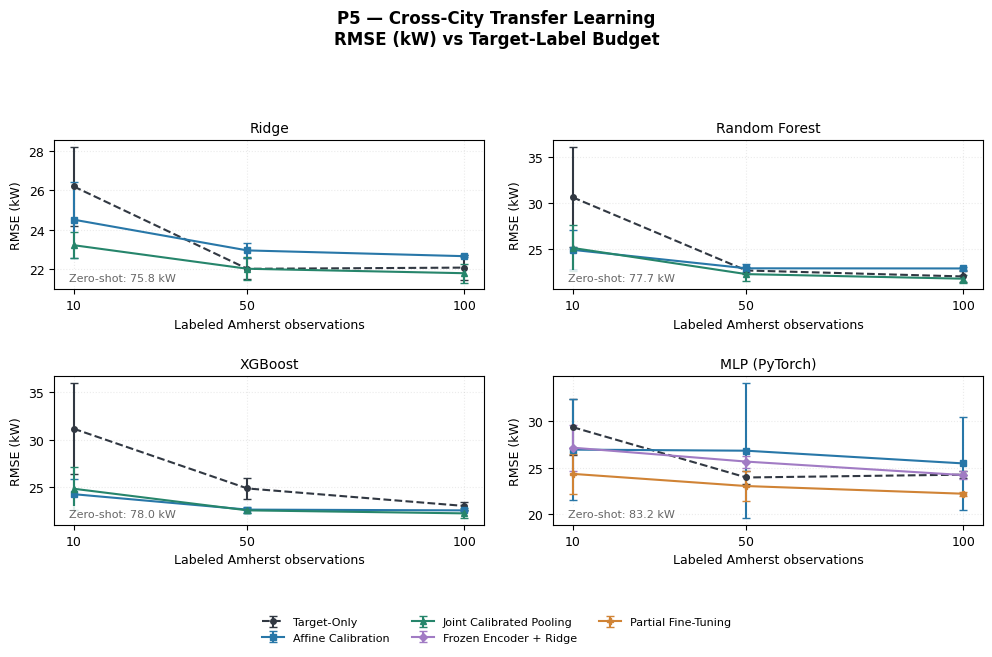

[SAVED] P5_MAE_Label_Efficiency_All_Models.pdf


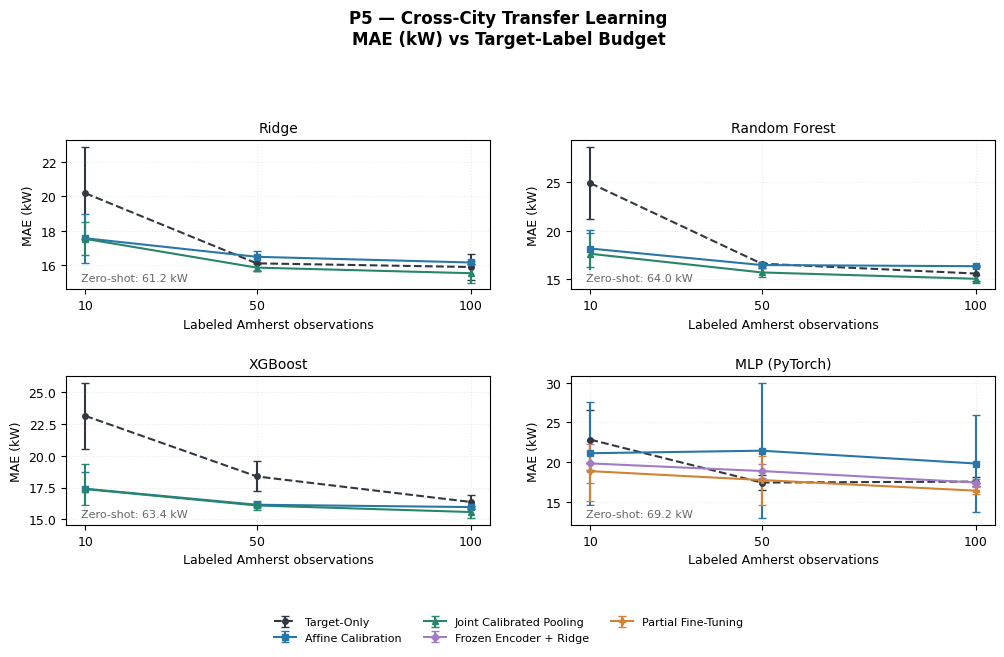

[SAVED] P5_RMSE_Transfer_Gains_All_Models.pdf


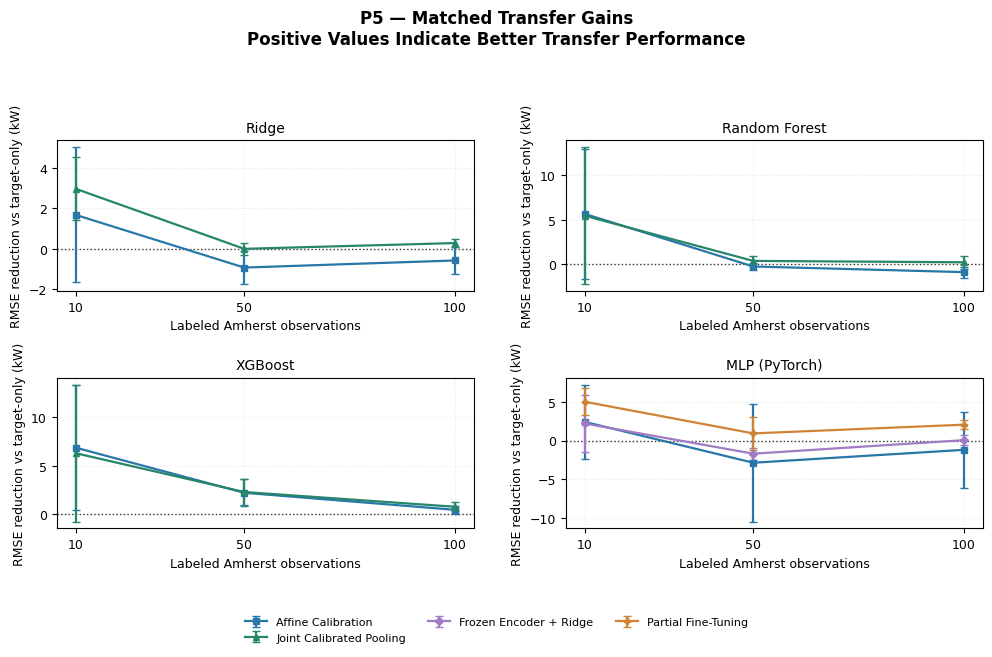

[SAVED] P5_Ridge_Prediction_Scatter_10_Labels.pdf


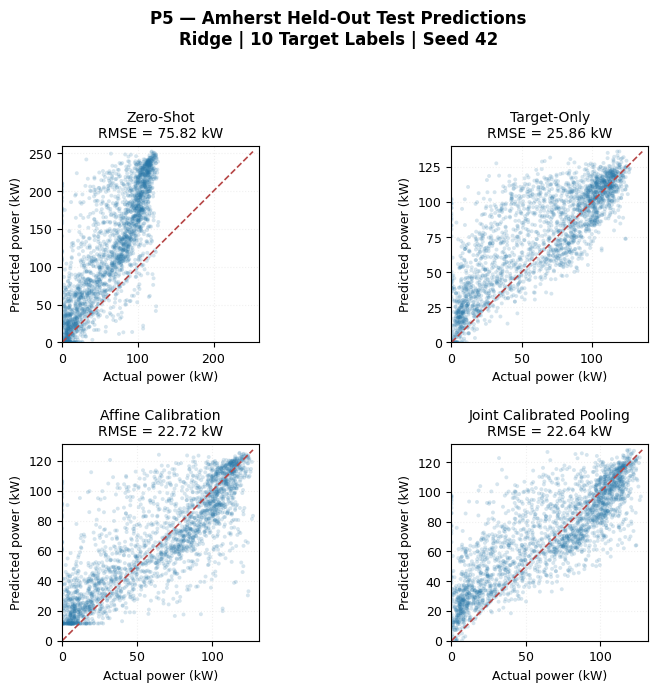

[SAVED] P5_Ridge_Prediction_Scatter_100_Labels.pdf


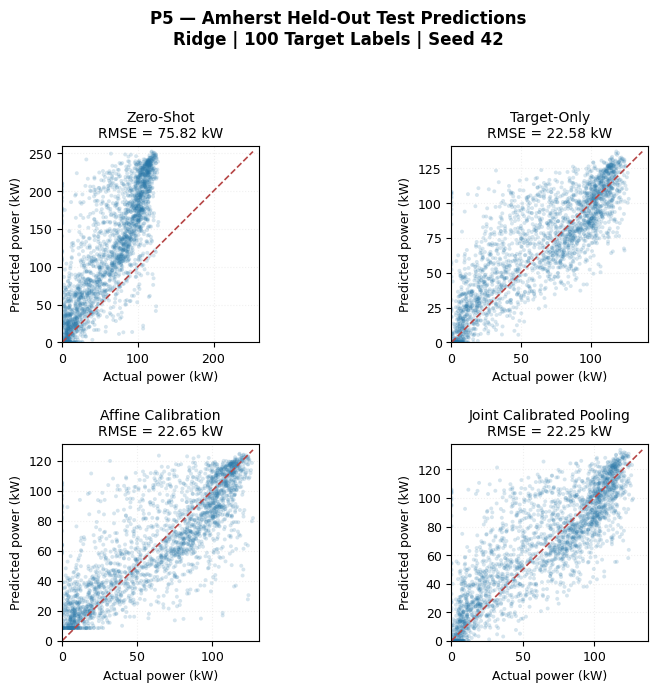


P5 — CONSOLIDATED TRANSFER-LEARNING RESULTS

Total model evaluations      : 129
Three-seed summary rows     : 43
Matched transfer evaluations: 81
Figures prepared            : 5
Save final vector PDFs      : True

OVERALL MATCHED TRANSFER COMPARISON


,Method,Evaluations,Improved,Mean_RMSE_Gain_kW,Median_RMSE_Gain_kW
0,Partial Fine-Tuning,9,8,2.6422,2.5432
1,Joint Calibrated Pooling,27,22,2.0796,0.7734
2,Affine Calibration,36,21,1.0522,0.2162
3,Frozen Encoder + Ridge,9,3,0.1805,-0.2036



LOWEST OBSERVED MEAN RMSE AT EACH LABEL BUDGET


,Target Labels,Method,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean
0,10,Joint Calibrated Pooling,Ridge,23.2242,0.6611,17.5213,18.2580
1,50,Target-Only,Ridge,22.0308,0.5333,16.0990,17.3198
2,100,Joint Calibrated Pooling,Random Forest,21.7990,0.4196,15.0267,17.1376



NORMALIZED RMSE LABEL-EFFICIENCY AUC GAINS
Positive AUC gains indicate lower average RMSE over the 10–100-label interval.


,Method,Model,Mean_AUC_Gain_kW,SD_AUC_Gain_kW,Runs
0,Affine Calibration,XGBoost,2.7591,2.0462,3
1,Joint Calibrated Pooling,XGBoost,2.7591,1.9737,3
2,Partial Fine-Tuning,MLP (PyTorch),2.1283,1.1811,3
3,Joint Calibrated Pooling,Random Forest,1.4808,2.1863,3
4,Affine Calibration,Random Forest,0.9046,1.9700,3
5,Joint Calibrated Pooling,Ridge,0.7376,0.4176,3
6,Affine Calibration,Ridge,-0.2523,1.3254,3
7,Frozen Encoder + Ridge,MLP (PyTorch),-0.3473,0.9861,3
8,Affine Calibration,MLP (PyTorch),-1.2272,6.1334,3



SAVED CONSOLIDATED FILES
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_All_Experiment_Metrics.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_All_Methods_Summary.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_Matched_Transfer_Gains.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_Matched_Transfer_Gains_Summary.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_Label_Efficiency_AUC.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_Label_Efficiency_AUC_Gains.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_RMSE_AUC_Gain_Summary.csv
  /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P5/P5_Descriptive_Best_Observed.csv

No models were trained or refitted.

All 5 PDF figur

In [8]:

# ============================================================
# P5 — Cell 8: Consolidated Evaluation and Final Figures
# ============================================================

import matplotlib.pyplot as plt

SAVE_P5_FIGURES = True

P5_RESULT_FILES = {
    "Zero-Shot": RESULTS_DIR / "zero_shot_metrics.csv",
    "Target-Only": RESULTS_DIR / "target_only_few_shot_metrics.csv",
    "Affine Calibration": RESULTS_DIR / "affine_calibration_metrics.csv",
    "Frozen Encoder + Ridge": RESULTS_DIR / "neural_transfer_metrics.csv",
    "Partial Fine-Tuning": RESULTS_DIR / "neural_transfer_metrics.csv",
    "Joint Calibrated Pooling": RESULTS_DIR / "joint_calibrated_pooling_metrics.csv"
}

P5_METHOD_STYLES = {
    "Target-Only": {
        "color": "#313842", "marker": "o", "linestyle": "--"
    },
    "Affine Calibration": {
        "color": "#2877a8", "marker": "s", "linestyle": "-"
    },
    "Joint Calibrated Pooling": {
        "color": "#26856b", "marker": "^", "linestyle": "-"
    },
    "Frozen Encoder + Ridge": {
        "color": "#a17bc4", "marker": "D", "linestyle": "-"
    },
    "Partial Fine-Tuning": {
        "color": "#d08335", "marker": "P", "linestyle": "-"
    }
}

P5_REQUIRED_METRICS = [
    "RMSE (kW)", "MAE (kW)", "nRMSE (%)", "R2"
]

P5_EXPERIMENT_KEYS = [
    "Method", "Model", "Target Labels", "Seed"
]


# ------------------------------------------------------------
# 1. Load and verify all saved experiments
# ------------------------------------------------------------

source_counts = {
    "Zero-Shot": 12,
    "Target-Only": 36,
    "Affine Calibration": 36,
    "Frozen Encoder + Ridge": 9,
    "Partial Fine-Tuning": 9,
    "Joint Calibrated Pooling": 27
}

all_frames = []

for method, path in P5_RESULT_FILES.items():

    if not path.is_file():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    if method in (
        "Frozen Encoder + Ridge",
        "Partial Fine-Tuning"
    ):
        df = df[df["Method"] == method].copy()

    else:
        df = df.copy()
        assert (df["Method"] == method).all()

    required = P5_EXPERIMENT_KEYS + P5_REQUIRED_METRICS

    missing = [
        column for column in required
        if column not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{method}: missing columns {missing}"
        )

    assert len(df) == source_counts[method], (
        f"{method}: unexpected result count {len(df)}"
    )

    assert not df.duplicated(P5_EXPERIMENT_KEYS).any()

    for metric in P5_REQUIRED_METRICS:
        assert np.isfinite(df[metric]).all()

    assert (df["RMSE (kW)"] >= 0).all()
    assert (df["MAE (kW)"] >= 0).all()

    all_frames.append(df[required])

P5_ALL_RESULTS = pd.concat(
    all_frames,
    ignore_index=True
)

assert len(P5_ALL_RESULTS) == 129

assert not P5_ALL_RESULTS.duplicated(
    P5_EXPERIMENT_KEYS
).any()

P5_ALL_RESULTS.to_csv(
    RESULTS_DIR / "P5_All_Experiment_Metrics.csv",
    index=False
)


# ------------------------------------------------------------
# 2. Three-seed summary of all models and approaches
# ------------------------------------------------------------

P5_ALL_SUMMARY = (
    P5_ALL_RESULTS.groupby(
        ["Method", "Model", "Target Labels"],
        as_index=False
    )
    .agg(
        RMSE_Mean=("RMSE (kW)", "mean"),
        RMSE_SD=("RMSE (kW)", "std"),
        MAE_Mean=("MAE (kW)", "mean"),
        MAE_SD=("MAE (kW)", "std"),
        nRMSE_Mean=("nRMSE (%)", "mean"),
        R2_Mean=("R2", "mean"),
        Runs=("Seed", "count")
    )
)

assert len(P5_ALL_SUMMARY) == 43
assert (P5_ALL_SUMMARY["Runs"] == 3).all()

P5_ALL_SUMMARY.to_csv(
    RESULTS_DIR / "P5_All_Methods_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 3. Calculate matched transfer gains
# ------------------------------------------------------------

target_reference = (
    P5_ALL_RESULTS[
        P5_ALL_RESULTS["Method"] == "Target-Only"
    ][
        [
            "Model", "Target Labels", "Seed",
            "RMSE (kW)", "MAE (kW)"
        ]
    ]
    .rename(columns={
        "RMSE (kW)": "Target_Only_RMSE",
        "MAE (kW)": "Target_Only_MAE"
    })
)

transfer_results = P5_ALL_RESULTS[
    ~P5_ALL_RESULTS["Method"].isin(
        ["Zero-Shot", "Target-Only"]
    )
].copy()

P5_MATCHED_GAINS = transfer_results.merge(
    target_reference,
    on=["Model", "Target Labels", "Seed"],
    how="inner",
    validate="many_to_one"
)

assert len(P5_MATCHED_GAINS) == 81

P5_MATCHED_GAINS["RMSE_Gain_kW"] = (
    P5_MATCHED_GAINS["Target_Only_RMSE"]
    - P5_MATCHED_GAINS["RMSE (kW)"]
)

P5_MATCHED_GAINS["MAE_Gain_kW"] = (
    P5_MATCHED_GAINS["Target_Only_MAE"]
    - P5_MATCHED_GAINS["MAE (kW)"]
)

P5_MATCHED_GAINS["RMSE_Reduction_pct"] = (
    100 * P5_MATCHED_GAINS["RMSE_Gain_kW"]
    / P5_MATCHED_GAINS["Target_Only_RMSE"]
)

P5_MATCHED_GAINS.to_csv(
    RESULTS_DIR / "P5_Matched_Transfer_Gains.csv",
    index=False
)

P5_GAIN_SUMMARY = (
    P5_MATCHED_GAINS.groupby(
        ["Method", "Model", "Target Labels"],
        as_index=False
    )
    .agg(
        RMSE_Gain_Mean=("RMSE_Gain_kW", "mean"),
        RMSE_Gain_SD=("RMSE_Gain_kW", "std"),
        MAE_Gain_Mean=("MAE_Gain_kW", "mean"),
        RMSE_Reduction_pct=(
            "RMSE_Reduction_pct", "mean"
        ),
        Improved_Seeds=(
            "RMSE_Gain_kW",
            lambda values: int((values > 0).sum())
        )
    )
)

P5_GAIN_SUMMARY.to_csv(
    RESULTS_DIR / "P5_Matched_Transfer_Gains_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Label-efficiency AUC: 10–100 target labels
# ------------------------------------------------------------

# Lower RMSE/MAE AUC means better label efficiency.
# The area is normalized by the width of the label range.
# The zero-shot point is not included in this integral.

auc_records = []

few_shot_results = P5_ALL_RESULTS[
    P5_ALL_RESULTS["Target Labels"] > 0
]

for (
    method, model, seed
), group in few_shot_results.groupby(
    ["Method", "Model", "Seed"]
):

    ordered = group.sort_values(
        "Target Labels"
    )

    x = ordered["Target Labels"].to_numpy(
        dtype=float
    )

    np.testing.assert_array_equal(
        x, [10, 50, 100]
    )

    for metric in ("RMSE (kW)", "MAE (kW)"):

        y = ordered[metric].to_numpy(
            dtype=float
        )

        area = float(np.trapezoid(y, x))

        auc_records.append({
            "Method": method,
            "Model": model,
            "Seed": int(seed),
            "Metric": metric,
            "AUC_10_to_100": area,
            "Normalized_AUC": area / 90.0
        })

P5_AUC = pd.DataFrame(auc_records)

assert len(P5_AUC) == 78

P5_AUC.to_csv(
    RESULTS_DIR / "P5_Label_Efficiency_AUC.csv",
    index=False
)

target_auc_reference = (
    P5_AUC[
        P5_AUC["Method"] == "Target-Only"
    ][
        ["Model", "Seed", "Metric", "Normalized_AUC"]
    ]
    .rename(columns={
        "Normalized_AUC": "Target_Only_AUC"
    })
)

P5_AUC_GAINS = (
    P5_AUC[
        P5_AUC["Method"] != "Target-Only"
    ]
    .merge(
        target_auc_reference,
        on=["Model", "Seed", "Metric"],
        how="inner",
        validate="many_to_one"
    )
)

assert len(P5_AUC_GAINS) == 54

P5_AUC_GAINS["AUC_Gain_kW"] = (
    P5_AUC_GAINS["Target_Only_AUC"]
    - P5_AUC_GAINS["Normalized_AUC"]
)

P5_AUC_GAINS.to_csv(
    RESULTS_DIR / "P5_Label_Efficiency_AUC_Gains.csv",
    index=False
)


# ------------------------------------------------------------
# 5. Figure settings
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

P5_FIGURE_COUNT = 0


def finalize_p5_figure(fig, filename):

    global P5_FIGURE_COUNT

    if SAVE_P5_FIGURES:

        path = FIGURES_DIR / filename

        fig.savefig(
            path,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:

        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)

    P5_FIGURE_COUNT += 1


def add_p5_figure_legend(fig, axes):

    handles_by_label = {}

    for ax in axes.ravel():

        handles, labels = ax.get_legend_handles_labels()

        for handle, label in zip(handles, labels):
            handles_by_label.setdefault(label, handle)

    fig.legend(
        handles_by_label.values(),
        handles_by_label.keys(),
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=3,
        frameon=False
    )


# ------------------------------------------------------------
# 6. RMSE and MAE label-efficiency curves
# ------------------------------------------------------------

for metric_name, mean_col, sd_col, slug in (
    ("RMSE (kW)", "RMSE_Mean", "RMSE_SD", "RMSE"),
    ("MAE (kW)", "MAE_Mean", "MAE_SD", "MAE")
):

    fig, axes = plt.subplots(
        2, 2,
        figsize=(10.0, 6.6)
    )

    for ax, model in zip(
        axes.ravel(),
        P5_BASELINE_MODELS
    ):

        for method, style in P5_METHOD_STYLES.items():

            subset = P5_ALL_SUMMARY[
                (P5_ALL_SUMMARY["Model"] == model)
                & (P5_ALL_SUMMARY["Method"] == method)
            ].sort_values("Target Labels")

            if subset.empty:
                continue

            assert len(subset) == 3

            ax.errorbar(
                subset["Target Labels"],
                subset[mean_col],
                yerr=subset[sd_col],
                color=style["color"],
                marker=style["marker"],
                linestyle=style["linestyle"],
                linewidth=1.5,
                markersize=4,
                capsize=3,
                label=method
            )

        # Display zero-shot performance as an annotation,
        # rather than stretching the vertical axis to 80 kW.
        zero = P5_ALL_SUMMARY[
            (P5_ALL_SUMMARY["Model"] == model)
            & (P5_ALL_SUMMARY["Method"] == "Zero-Shot")
        ]

        assert len(zero) == 1

        ax.text(
            0.035, 0.055,
            f"Zero-shot: {zero.iloc[0][mean_col]:.1f} kW",
            transform=ax.transAxes,
            fontsize=8,
            color="#666666",
            bbox={
                "facecolor": "white",
                "alpha": 0.85,
                "edgecolor": "none",
                "pad": 2
            }
        )

        ax.set_title(model)
        ax.set_xlabel("Labeled Amherst observations")
        ax.set_ylabel(metric_name)
        ax.set_xticks(TARGET_LABEL_BUDGETS)
        ax.grid(alpha=0.25, linestyle=":")

    fig.suptitle(
        f"P5 — Cross-City Transfer Learning\n"
        f"{metric_name} vs Target-Label Budget",
        fontsize=12,
        fontweight="semibold"
    )

    add_p5_figure_legend(fig, axes)

    fig.tight_layout(
        rect=(0, 0.115, 1, 0.91),
        h_pad=2.1,
        w_pad=2.0
    )

    finalize_p5_figure(
        fig,
        f"P5_{slug}_Label_Efficiency_All_Models.pdf"
    )


# ------------------------------------------------------------
# 7. Matched RMSE gain curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10.0, 6.6)
)

for ax, model in zip(
    axes.ravel(),
    P5_BASELINE_MODELS
):

    ax.axhline(
        0,
        color="#333333",
        linewidth=1.0,
        linestyle=":"
    )

    for method, style in P5_METHOD_STYLES.items():

        if method == "Target-Only":
            continue

        subset = P5_GAIN_SUMMARY[
            (P5_GAIN_SUMMARY["Model"] == model)
            & (P5_GAIN_SUMMARY["Method"] == method)
        ].sort_values("Target Labels")

        if subset.empty:
            continue

        ax.errorbar(
            subset["Target Labels"],
            subset["RMSE_Gain_Mean"],
            yerr=subset["RMSE_Gain_SD"],
            color=style["color"],
            marker=style["marker"],
            linestyle=style["linestyle"],
            linewidth=1.6,
            markersize=4,
            capsize=3,
            label=method
        )

    ax.set_title(model)
    ax.set_xlabel("Labeled Amherst observations")
    ax.set_ylabel("RMSE reduction vs target-only (kW)")
    ax.set_xticks(TARGET_LABEL_BUDGETS)
    ax.grid(alpha=0.25, linestyle=":")

fig.suptitle(
    "P5 — Matched Transfer Gains\n"
    "Positive Values Indicate Better Transfer Performance",
    fontsize=12,
    fontweight="semibold"
)

add_p5_figure_legend(fig, axes)

fig.tight_layout(
    rect=(0, 0.11, 1, 0.91),
    h_pad=2.1,
    w_pad=2.0
)

finalize_p5_figure(
    fig,
    "P5_RMSE_Transfer_Gains_All_Models.pdf"
)


# ------------------------------------------------------------
# 8. Load prediction files for a fixed Ridge comparison
# ------------------------------------------------------------

def load_p5_saved_prediction(
    method, model, budget, seed
):

    if method == "Zero-Shot":

        path = p5_prediction_path(
            "Zero-Shot", model, 0, seed
        )

    elif method == "Target-Only":

        path = p5_prediction_path(
            "Target-Only", model, budget, seed
        )

    elif method == "Affine Calibration":

        path = p5_calibration_prediction_path(
            model, budget, seed
        )

    elif method == "Joint Calibrated Pooling":

        path = p5_joint_prediction_path(
            model, budget, seed
        )

    elif method in (
        "Frozen Encoder + Ridge",
        "Partial Fine-Tuning"
    ):

        if model != "MLP (PyTorch)":
            raise ValueError(
                "Neural transfer requires the MLP model."
            )

        path = p5_nt_prediction_path(
            method, budget, seed
        )

    else:
        raise ValueError(method)

    if not path.is_file():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as saved:

        row_index = saved["row_index"].copy()
        y_true = saved["y_true"].copy()
        y_pred = saved["y_pred"].copy()

    np.testing.assert_array_equal(
        row_index,
        target["test_row_index"]
    )

    np.testing.assert_allclose(
        y_true,
        target["y_test"]
    )

    assert y_pred.shape == y_true.shape
    assert np.isfinite(y_pred).all()

    return y_true, y_pred


# ------------------------------------------------------------
# 9. Prediction-versus-ground-truth figures
# ------------------------------------------------------------

# Ridge and seed 42 are fixed for these diagnostic figures.
# The figures are illustrative and are not used for model
# selection or for any training decision.

diagnostic_methods = (
    "Zero-Shot",
    "Target-Only",
    "Affine Calibration",
    "Joint Calibrated Pooling"
)

for budget in (10, 100):

    fig, axes = plt.subplots(
        2, 2,
        figsize=(8.0, 7.0)
    )

    for ax, method in zip(
        axes.ravel(),
        diagnostic_methods
    ):

        actual, predicted = load_p5_saved_prediction(
            method=method,
            model="Ridge",
            budget=budget,
            seed=42
        )

        upper = max(
            float(np.max(actual)),
            float(np.max(predicted))
        )

        ax.scatter(
            actual,
            predicted,
            s=8,
            alpha=0.19,
            color="#2877a8",
            edgecolors="none",
            rasterized=True
        )

        ax.plot(
            [0, upper],
            [0, upper],
            color="#b64646",
            linestyle="--",
            linewidth=1.2,
            label="Perfect prediction"
        )

        rmse = float(
            np.sqrt(np.mean(
                (actual - predicted) ** 2
            ))
        )

        ax.set_title(
            f"{method}\nRMSE = {rmse:.2f} kW"
        )

        ax.set_xlabel("Actual power (kW)")
        ax.set_ylabel("Predicted power (kW)")

        ax.set_xlim(0, upper * 1.03)
        ax.set_ylim(0, upper * 1.03)

        ax.set_aspect(
            "equal",
            adjustable="box"
        )

        ax.grid(alpha=0.18, linestyle=":")

    fig.suptitle(
        "P5 — Amherst Held-Out Test Predictions\n"
        f"Ridge | {budget} Target Labels | Seed 42",
        fontsize=12,
        fontweight="semibold"
    )

    fig.tight_layout(
        rect=(0, 0, 1, 0.93),
        h_pad=2.0,
        w_pad=1.7
    )

    finalize_p5_figure(
        fig,
        f"P5_Ridge_Prediction_Scatter_"
        f"{budget}_Labels.pdf"
    )


# ------------------------------------------------------------
# 10. Summarize label-efficiency AUC gains
# ------------------------------------------------------------

auc_gain_summary = (
    P5_AUC_GAINS[
        P5_AUC_GAINS["Metric"] == "RMSE (kW)"
    ]
    .groupby(
        ["Method", "Model"],
        as_index=False
    )
    .agg(
        Mean_AUC_Gain_kW=("AUC_Gain_kW", "mean"),
        SD_AUC_Gain_kW=("AUC_Gain_kW", "std"),
        Runs=("Seed", "count")
    )
    .sort_values(
        "Mean_AUC_Gain_kW",
        ascending=False
    )
)

assert (auc_gain_summary["Runs"] == 3).all()

auc_gain_summary.to_csv(
    RESULTS_DIR / "P5_RMSE_AUC_Gain_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 11. Descriptive comparison across approaches
# ------------------------------------------------------------

# This leaderboard compares observed test-set means.
# It is NOT a validation-based model-selection procedure.

observed_best = (
    P5_ALL_SUMMARY[
        P5_ALL_SUMMARY["Target Labels"] > 0
    ]
    .sort_values("RMSE_Mean")
    .drop_duplicates("Target Labels")
    .sort_values("Target Labels")
)

observed_best.to_csv(
    RESULTS_DIR / "P5_Descriptive_Best_Observed.csv",
    index=False
)

method_comparison = (
    P5_MATCHED_GAINS.groupby(
        "Method",
        as_index=False
    )
    .agg(
        Evaluations=("RMSE_Gain_kW", "size"),
        Improved=("RMSE_Gain_kW", lambda x: int((x > 0).sum())),
        Mean_RMSE_Gain_kW=("RMSE_Gain_kW", "mean"),
        Median_RMSE_Gain_kW=("RMSE_Gain_kW", "median")
    )
    .sort_values(
        "Mean_RMSE_Gain_kW",
        ascending=False
    )
)

print("\n" + "=" * 75)
print("P5 — CONSOLIDATED TRANSFER-LEARNING RESULTS")
print("=" * 75)

print(f"\nTotal model evaluations      : {len(P5_ALL_RESULTS)}")
print(f"Three-seed summary rows     : {len(P5_ALL_SUMMARY)}")
print(f"Matched transfer evaluations: {len(P5_MATCHED_GAINS)}")
print(f"Figures prepared            : {P5_FIGURE_COUNT}")
print(f"Save final vector PDFs      : {SAVE_P5_FIGURES}")

print("\nOVERALL MATCHED TRANSFER COMPARISON")
display(
    method_comparison.round(4).reset_index(drop=True)
)

print("\nLOWEST OBSERVED MEAN RMSE AT EACH LABEL BUDGET")
display(
    observed_best[
        [
            "Target Labels",
            "Method",
            "Model",
            "RMSE_Mean",
            "RMSE_SD",
            "MAE_Mean",
            "nRMSE_Mean"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nNORMALIZED RMSE LABEL-EFFICIENCY AUC GAINS")
print(
    "Positive AUC gains indicate lower average RMSE "
    "over the 10–100-label interval."
)

display(
    auc_gain_summary.round(4).reset_index(drop=True)
)

print("\nSAVED CONSOLIDATED FILES")

for filename in (
    "P5_All_Experiment_Metrics.csv",
    "P5_All_Methods_Summary.csv",
    "P5_Matched_Transfer_Gains.csv",
    "P5_Matched_Transfer_Gains_Summary.csv",
    "P5_Label_Efficiency_AUC.csv",
    "P5_Label_Efficiency_AUC_Gains.csv",
    "P5_RMSE_AUC_Gain_Summary.csv",
    "P5_Descriptive_Best_Observed.csv"
):
    print(f"  {RESULTS_DIR / filename}")

print("\nNo models were trained or refitted.")

if SAVE_P5_FIGURES:

    print(
        f"\nAll {P5_FIGURE_COUNT} PDF figures "
        "were exported."
    )

else:

    print(
        "\nFigures are in preview mode. "
        "Set SAVE_P5_FIGURES=True and rerun "
        "this cell to export the PDFs."
    )
